In [1]:
import sys
import os

print("Python:", sys.version)
print("Carpeta de trabajo:", os.getcwd())

Python: 3.13.17 (tags/v3.13.17:64e080d, Oct 21 2026, 14:08:53) [MSC v.1944 64 bit (AMD64)]
Carpeta de trabajo: C:\Users\Usuario\SocialTOX


In [2]:
from pathlib import Path

carpetas = [
    "data/raw",
    "data/processed",
    "notebooks",
    "models",
    "backend",
    "frontend"
]

for carpeta in carpetas:
    Path(carpeta).mkdir(parents=True, exist_ok=True)

print("¡Carpetas creadas correctamente!")

¡Carpetas creadas correctamente!


In [3]:
from pathlib import Path

DATA_DIR = Path("data/raw")

print("Archivos encontrados:")

for archivo in DATA_DIR.iterdir():
    print(archivo.name)

Archivos encontrados:
OffendES
toxicity_cons_hf_test.tsv
toxicity_cons_hf_train.tsv


In [4]:
from pathlib import Path

print("Carpeta principal:")
for elemento in Path(".").iterdir():
    print(elemento.name)

print("\nContenido de data:")
for elemento in Path("data").rglob("*"):
    print(elemento)

Carpeta principal:
.ipynb_checkpoints
01_exploracion.ipynb
backend
data
frontend
models
notebooks
requirements.txt
socialtox_predictor.py
socialtox_preprocesamiento.py
untitled.py
venv
__pycache__

Contenido de data:
data\processed
data\raw
data\raw\OffendES
data\raw\toxicity_cons_hf_test.tsv
data\raw\toxicity_cons_hf_train.tsv
data\raw\OffendES\dev_set.tsv
data\raw\OffendES\test_set.tsv
data\raw\OffendES\training_set.tsv


In [5]:
from pathlib import Path

for archivo in Path("data/raw").iterdir():
    print(archivo.name)

OffendES
toxicity_cons_hf_test.tsv
toxicity_cons_hf_train.tsv


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar los archivos
train = pd.read_csv(
    "data/raw/toxicity_cons_hf_train.tsv",
    sep="\t"
)

test = pd.read_csv(
    "data/raw/toxicity_cons_hf_test.tsv",
    sep="\t"
)

print("Entrenamiento:", train.shape)
print("Prueba:", test.shape)
print("Total:", len(train) + len(test))

Entrenamiento: (3043, 4)
Prueba: (968, 4)
Total: 4011


In [7]:
display(train.head())

,id,text,CONST,TOXICIDAD
0,298,Qué forma más horrorosa de morir. Apaleada (po...,no,2. Ligeramente tóxico
1,2792,Falta por poner como turistas a los que vengan...,sí,2. Ligeramente tóxico
2,139,No sé González pero Rajoy tras un primer manda...,sí,2. Ligeramente tóxico
3,535,@berberecho #195 que no fue sado porque salió ...,no,1. No tóxico
4,945,#5: Da igual que se hable del master de cifuen...,no,2. Ligeramente tóxico


In [8]:
print("Columnas:")
print(train.columns.tolist())

print("\nInformación:")
train.info()

print("\nValores nulos:")
display(train.isnull().sum())

Columnas:
['id', 'text', 'CONST', 'TOXICIDAD']

Información:
<class 'pandas.DataFrame'>
RangeIndex: 3043 entries, 0 to 3042
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   id         3043 non-null   int64
 1   text       3043 non-null   str  
 2   CONST      3043 non-null   str  
 3   TOXICIDAD  3043 non-null   str  
dtypes: int64(1), str(3)
memory usage: 95.2 KB

Valores nulos:


id           0
text         0
CONST        0
TOXICIDAD    0
dtype: int64

In [9]:
print("¡Hola SocialTOX!")
print("Jupyter está funcionando correctamente.")

¡Hola SocialTOX!
Jupyter está funcionando correctamente.


In [10]:
# Contar las categorías de toxicidad
distribucion = train["TOXICIDAD"].value_counts()

print("Distribución de toxicidad:")
display(distribucion)

# Calcular porcentajes
porcentajes = train["TOXICIDAD"].value_counts(normalize=True) * 100

print("\nPorcentajes:")
display(porcentajes.round(2))

Distribución de toxicidad:


TOXICIDAD
2. Ligeramente tóxico    1243
1. No tóxico             1052
3. Tóxico                 748
Name: count, dtype: int64


Porcentajes:


TOXICIDAD
2. Ligeramente tóxico    40.85
1. No tóxico             34.57
3. Tóxico                24.58
Name: proportion, dtype: float64

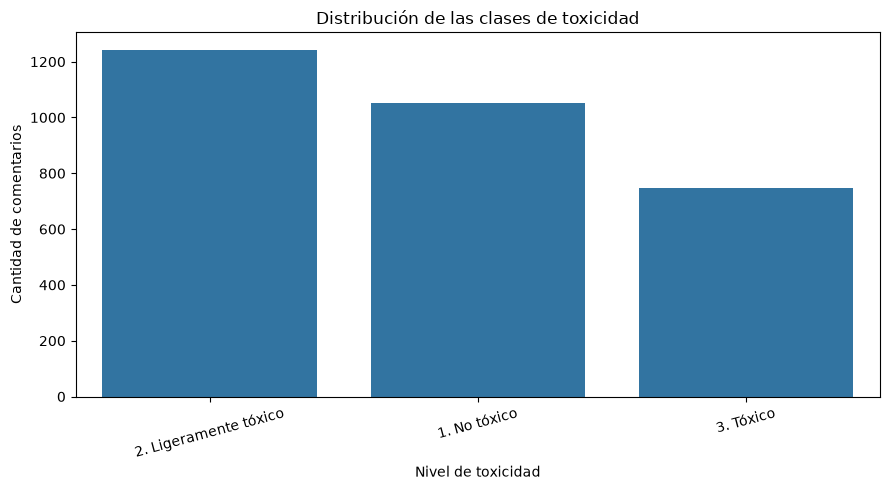

In [11]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=train,
    x="TOXICIDAD",
    order=train["TOXICIDAD"].value_counts().index
)

plt.title("Distribución de las clases de toxicidad")
plt.xlabel("Nivel de toxicidad")
plt.ylabel("Cantidad de comentarios")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [12]:
# Calcular la longitud de cada comentario
train["longitud"] = train["text"].astype(str).apply(len)

# Estadísticas generales
print("Estadísticas de longitud de los comentarios:")
display(train["longitud"].describe().round(2))

Estadísticas de longitud de los comentarios:


count    3043.00
mean      197.08
std       236.51
min         3.00
25%        55.00
50%       116.00
75%       257.00
max      4800.00
Name: longitud, dtype: float64

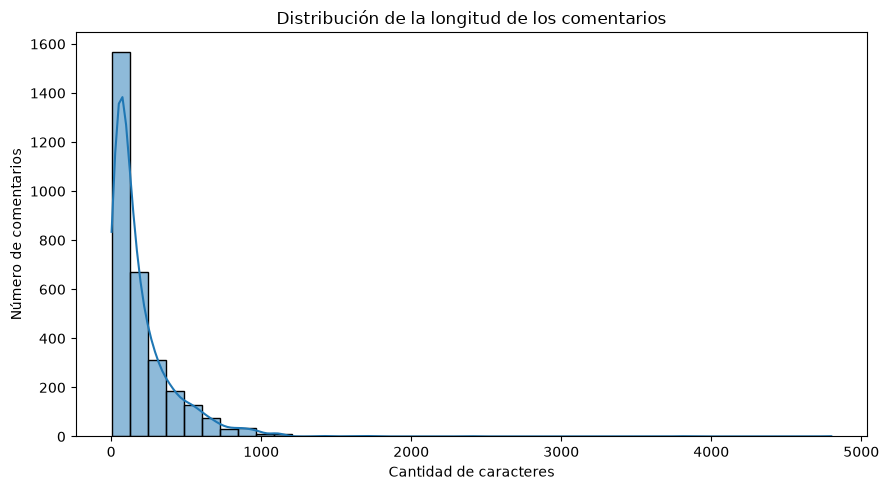

In [13]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=train,
    x="longitud",
    bins=40,
    kde=True
)

plt.title("Distribución de la longitud de los comentarios")
plt.xlabel("Cantidad de caracteres")
plt.ylabel("Número de comentarios")
plt.tight_layout()
plt.show()

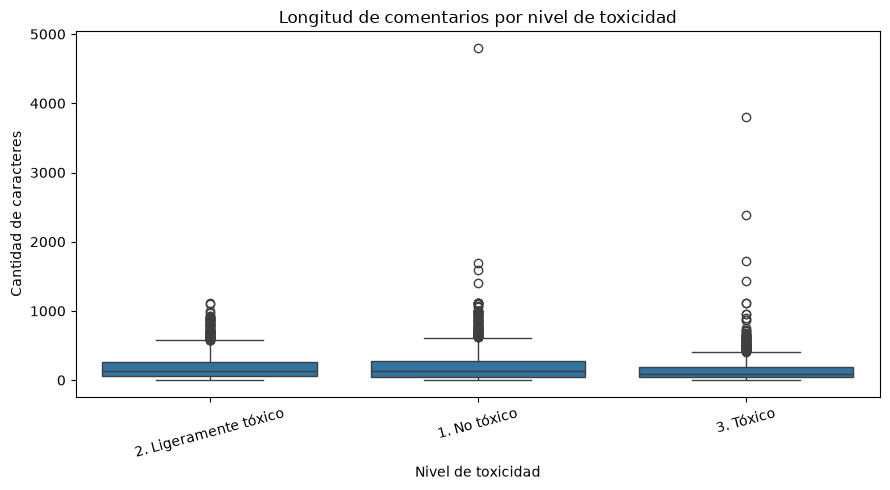

In [14]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=train,
    x="TOXICIDAD",
    y="longitud"
)

plt.title("Longitud de comentarios por nivel de toxicidad")
plt.xlabel("Nivel de toxicidad")
plt.ylabel("Cantidad de caracteres")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [15]:
%whos


Variable       Type           Data/Info
---------------------------------------
DATA_DIR       WindowsPath    data\raw
Path           type           <class 'pathlib._local.Path'>
archivo        WindowsPath    data\raw\toxicity_cons_hf_train.tsv
carpeta        str            frontend
carpetas       list           n=6
distribucion   Series         Shape: (3,)
elemento       WindowsPath    data\raw\OffendES\training_set.tsv
np             module         <module 'numpy' from 'C:\<...>ges\\numpy\\__init__.py'>
os             module         <module 'os' (frozen)>
pd             module         <module 'pandas' from 'C:<...>es\\pandas\\__init__.py'>
plt            module         <module 'matplotlib.pyplo<...>\\matplotlib\\pyplot.py'>
porcentajes    Series         Shape: (3,)
sns            module         <module 'seaborn' from 'C<...>s\\seaborn\\__init__.py'>
sys            module         <module 'sys' (built-in)>
test           DataFrame      Shape: (968, 4)
train          DataFrame      Shap

In [16]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer

# Palabras comunes del español (stopwords)
stopwords_es = {
    'de', 'la', 'que', 'el', 'en', 'y', 'a', 'los', 'del',
    'se', 'las', 'por', 'un', 'para', 'con', 'no', 'una',
    'su', 'al', 'lo', 'como', 'mas', 'pero', 'sus', 'le',
    'ya', 'o', 'este', 'si', 'porque', 'esta', 'entre',
    'cuando', 'muy', 'sin', 'sobre', 'tambien', 'me',
    'hasta', 'hay', 'donde', 'quien', 'desde', 'todo',
    'nos', 'durante', 'todos', 'uno', 'les', 'ni',
    'contra', 'otros', 'ese', 'eso', 'ante', 'ellos',
    'esto', 'mi', 'mis', 'tu', 'te', 'es', 'son',
    'fue', 'ser', 'estar', 'está', 'han', 'he',
    'más', 'qué', 'cómo', 'sí', 'así'
}

# Utilizamos los comentarios del conjunto de entrenamiento
comentarios = train['text'].fillna('').astype(str)

# Calcular frecuencia de palabras
vectorizador = CountVectorizer(
    lowercase=True,
    stop_words=list(stopwords_es),
    token_pattern=r'(?u)\b[a-záéíóúüñ]{3,}\b',
    min_df=2
)

matriz = vectorizador.fit_transform(comentarios)

frecuencias = pd.DataFrame({
    'palabra': vectorizador.get_feature_names_out(),
    'frecuencia': matriz.sum(axis=0).A1
})

# Ordenar de mayor a menor frecuencia
frecuencias = frecuencias.sort_values(
    by='frecuencia',
    ascending=False
)

# Mostrar las 30 palabras más frecuentes
display(frecuencias.head(30))


,palabra,frecuencia
1971,españa,304
5268,tiene,220
2420,gobierno,184
3575,nada,175
5054,solo,151
175,ahora,147
4433,puede,139
3948,país,138
577,bien,135
4440,pues,132


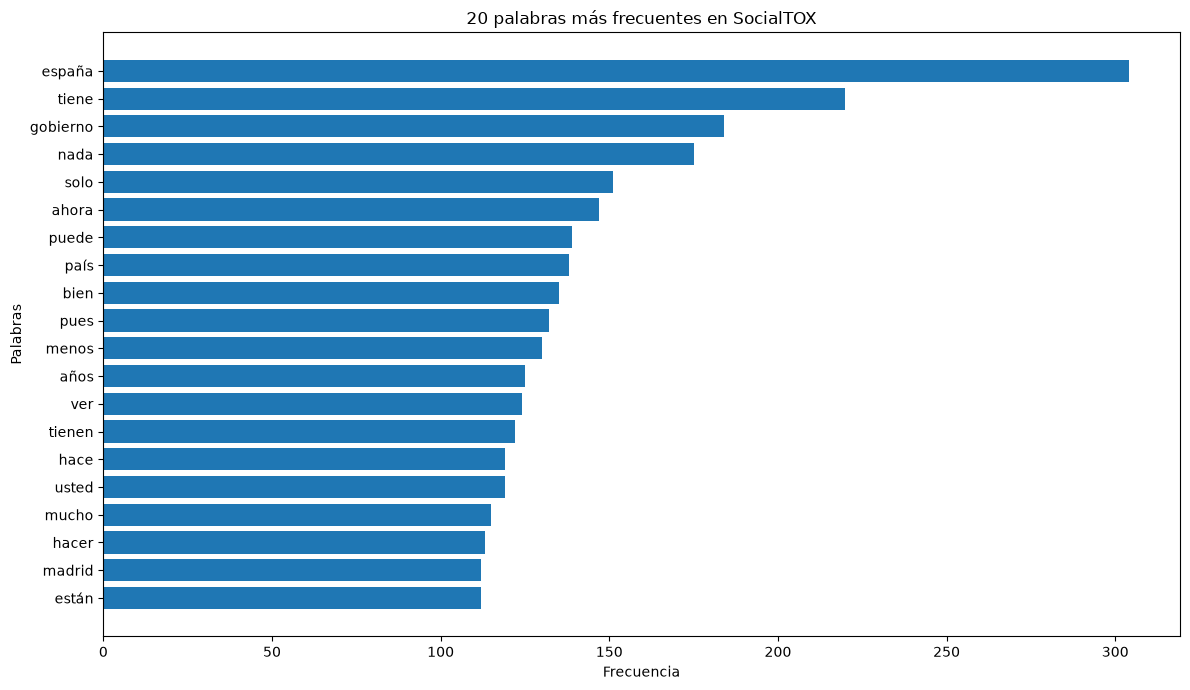

In [17]:

top_palabras = frecuencias.head(20).sort_values(
    by='frecuencia'
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_palabras['palabra'],
    top_palabras['frecuencia']
)

plt.title('20 palabras más frecuentes en SocialTOX')
plt.xlabel('Frecuencia')
plt.ylabel('Palabras')

plt.tight_layout()
plt.show()


In [18]:
print("Columnas del entrenamiento:")
print(train.columns.tolist())

print("\nDistribución de toxicidad:")
print(train['TOXICIDAD'].value_counts())


Columnas del entrenamiento:
['id', 'text', 'CONST', 'TOXICIDAD', 'longitud']

Distribución de toxicidad:
TOXICIDAD
2. Ligeramente tóxico    1243
1. No tóxico             1052
3. Tóxico                 748
Name: count, dtype: int64


In [19]:

# Analizar las palabras frecuentes por categoría de toxicidad

for categoria in train['TOXICIDAD'].unique():

    print("\n" + "=" * 60)
    print("CATEGORÍA:", categoria)
    print("=" * 60)

    # Seleccionar comentarios de la categoría
    textos = train.loc[
        train['TOXICIDAD'] == categoria, 'text'
    ].fillna('').astype(str)

    # Crear vectorizador
    vectorizador_cat = CountVectorizer(
        lowercase=True,
        stop_words=list(stopwords_es),
        token_pattern=r'(?u)\b[a-záéíóúüñ]{3,}\b',
        min_df=2
    )

    matriz_cat = vectorizador_cat.fit_transform(textos)

    # Calcular frecuencias
    tabla = pd.DataFrame({
        'palabra': vectorizador_cat.get_feature_names_out(),
        'apariciones': matriz_cat.sum(axis=0).A1
    })

    # Normalizar por cantidad de comentarios
    tabla['por_1000_comentarios'] = (
        tabla['apariciones'] / len(textos) * 1000
    ).round(2)

    tabla = tabla.sort_values(
        by='apariciones',
        ascending=False
    )

    display(tabla.head(15))



CATEGORÍA: 2. Ligeramente tóxico


,palabra,apariciones,por_1000_comentarios
865,españa,121,97.35
2415,tiene,92,74.01
1628,nada,84,67.58
66,ahora,67,53.90
1797,país,67,53.90
1076,gobierno,65,52.29
2030,pues,62,49.88
2416,tienen,60,48.27
2565,ver,59,47.47
1509,menos,58,46.66



CATEGORÍA: 1. No tóxico


,palabra,apariciones,por_1000_comentarios
868,españa,98,93.16
2363,tiene,76,72.24
248,bien,60,57.03
1068,gobierno,60,57.03
2254,solo,58,55.13
1590,nada,58,55.13
1975,puede,56,53.23
2311,también,52,49.43
72,ahora,52,49.43
1115,hace,52,49.43



CATEGORÍA: 3. Tóxico


,palabra,apariciones,por_1000_comentarios
459,españa,85,113.64
589,gobierno,59,78.88
1375,tiene,52,69.52
1325,solo,36,48.13
1144,psoe,35,46.79
914,nada,33,44.12
483,estos,32,42.78
1486,virus,30,40.11
798,madrid,30,40.11
1466,ver,29,38.77


In [20]:

# Seleccionar 5 comentarios aleatorios por categoría

for categoria in sorted(train['TOXICIDAD'].unique()):

    print("\n" + "=" * 70)
    print("CATEGORÍA:", categoria)
    print("=" * 70)

    muestra = train.loc[
        train['TOXICIDAD'] == categoria,
        ['text', 'TOXICIDAD']
    ].sample(n=5, random_state=42)

    for i, comentario in enumerate(muestra['text'], 1):
        print(f"\nComentario {i}:")
        print(comentario)



CATEGORÍA: 1. No tóxico

Comentario 1:
Más del 80% de los hospitales públicos españoles se construyeron después de la muerte de Franco. En las zonas rurales sólo había médicos privados y en aquellas en las que había claro, que la mayoría ni eso tenían.   Y los colegios fuera de las ciudades o incluso en barrios de la periferia eran "unitarias" en las que entraban de canto todos los niños a los que enseñaba un único profesor y sin apenas medios materiales.

Comentario 2:
Un Pacto para seguir epatando a los cuatro vientos ... tenemos la mejor Sanidad del mundo mundial y gratuita. Si, si, con ese cuajo.

Comentario 3:
@llopis00 #39 lo ha clavado

Comentario 4:
En cuanto al presidente de México: ¿Por qué no le reclama a Estados Unidos, los 2,5 millones de kilómetros cuadrados que los anglos le quitaron a los mexicanos en el Siglo XIX: los estados de Arizona, Nuevo Méjico, California, Colorado, parte de Nevada? Se los cargaron a todos y los pobres que resistieron, fueron llevados a las res

In [21]:

# Identificar comentarios repetidos con diferentes etiquetas

repetidos = train.groupby('text')['TOXICIDAD'].agg(
    cantidad='count',
    etiquetas_diferentes='nunique'
)

conflictos = repetidos[
    repetidos['etiquetas_diferentes'] > 1
]

print("Comentarios con etiquetas contradictorias:",
      len(conflictos))

print("\nTotal de comentarios duplicados:",
      train['text'].duplicated().sum())

# Mostrar algunos ejemplos
if len(conflictos) > 0:
    ejemplos = train[
        train['text'].isin(conflictos.index)
    ].sort_values('text')

    display(ejemplos[['text', 'TOXICIDAD']].head(10))


Comentarios con etiquetas contradictorias: 0

Total de comentarios duplicados: 1


In [22]:
duplicados = train[
    train.duplicated(subset=['text'], keep=False)
].sort_values('text')

display(duplicados[['id', 'text', 'TOXICIDAD']])

,id,text,TOXICIDAD
956,2376,Son dialectos,1. No tóxico
1882,2419,Son dialectos,1. No tóxico


In [23]:
# Eliminar comentarios duplicados conservando el primero
train = train.drop_duplicates(
    subset=['text'],
    keep='first'
).reset_index(drop=True)

print("Registros después de eliminar duplicados:", len(train))
print("Duplicados restantes:", train['text'].duplicated().sum())


Registros después de eliminar duplicados: 3042
Duplicados restantes: 0


In [24]:
print("=== ENTRENAMIENTO ===")
print("Dimensiones:", train.shape)
print("Columnas:", train.columns.tolist())

print("\nValores nulos:")
print(train[['text', 'TOXICIDAD']].isnull().sum())

print("\nDistribución de clases:")
print(train['TOXICIDAD'].value_counts())

print("\n=== PRUEBA ===")
print("Dimensiones:", test.shape)
print("Columnas:", test.columns.tolist())

print("\nPrimeros registros:")
display(test.head())

print("\n=== COLUMNAS CREADAS ===")
print("text_limpio existe:", 'text_limpio' in train.columns)

=== ENTRENAMIENTO ===
Dimensiones: (3042, 5)
Columnas: ['id', 'text', 'CONST', 'TOXICIDAD', 'longitud']

Valores nulos:
text         0
TOXICIDAD    0
dtype: int64

Distribución de clases:
TOXICIDAD
2. Ligeramente tóxico    1243
1. No tóxico             1051
3. Tóxico                 748
Name: count, dtype: int64

=== PRUEBA ===
Dimensiones: (968, 4)
Columnas: ['id', 'text', 'TOXICIDAD', 'CONST']

Primeros registros:


,id,text,TOXICIDAD,CONST
0,575,"Y ademas sin hacer un ""Atleti"" (Cerrojazo anti...",1. No tóxico,sí
1,259,#180Como lo dice USA es palabra de Dios!! USA ...,1. No tóxico,no
2,388,"#551Je Je Je, de verdad has pensado o releído ...",1. No tóxico,no
3,495,"En diciembre de 2018, su salida a Bolsa se con...",1. No tóxico,sí
4,70,Muchas gracias Ayuso!..Eres la más grande!,1. No tóxico,no



=== COLUMNAS CREADAS ===
text_limpio existe: False


In [25]:
print("=== COMPROBACIÓN DE IDs ===")

ids_compartidos = set(train['id']) & set(test['id'])

print("IDs compartidos:", len(ids_compartidos))

print("\n=== COMPROBACIÓN DE TEXTOS ===")

textos_compartidos = set(train['text']) & set(test['text'])

print("Textos compartidos:", len(textos_compartidos))

print("\n=== DISTRIBUCIÓN DEL TEST ===")

print(test['TOXICIDAD'].value_counts())

print("\nPorcentajes:")
print((test['TOXICIDAD'].value_counts(normalize=True) * 100).round(2))

=== COMPROBACIÓN DE IDs ===
IDs compartidos: 968

=== COMPROBACIÓN DE TEXTOS ===
Textos compartidos: 0

=== DISTRIBUCIÓN DEL TEST ===
TOXICIDAD
2. Ligeramente tóxico    439
1. No tóxico             381
3. Tóxico                148
Name: count, dtype: int64

Porcentajes:
TOXICIDAD
2. Ligeramente tóxico    45.35
1. No tóxico             39.36
3. Tóxico                15.29
Name: proportion, dtype: float64


In [26]:
print("=== IDs DUPLICADOS DENTRO DE TRAIN ===")
print("IDs duplicados:", train['id'].duplicated().sum())

print("\n=== IDs DUPLICADOS DENTRO DE TEST ===")
print("IDs duplicados:", test['id'].duplicated().sum())

print("\n=== EJEMPLOS DE IDs COMPARTIDOS ===")

ejemplos = list(ids_compartidos)[:10]

comparacion = train[train['id'].isin(ejemplos)][['id', 'text', 'TOXICIDAD']].merge(
    test[test['id'].isin(ejemplos)][['id', 'text', 'TOXICIDAD']],
    on='id',
    suffixes=('_train', '_test')
)

display(comparacion)

=== IDs DUPLICADOS DENTRO DE TRAIN ===
IDs duplicados: 0

=== IDs DUPLICADOS DENTRO DE TEST ===
IDs duplicados: 0

=== EJEMPLOS DE IDs COMPARTIDOS ===


,id,text_train,TOXICIDAD_train,text_test,TOXICIDAD_test
0,0,"Escándaloooo, es un escándalooo... Aunque lame...",2. Ligeramente tóxico,#55VOX.... son los que están metiendo con sus ...,2. Ligeramente tóxico
1,7,Otra institución devaluada. La porquería ajena...,3. Tóxico,"#91Bueno, ahora le dejo. En mi país tenemos la...",2. Ligeramente tóxico
2,8,#170Yo incluso añadiría si es posible que esos...,2. Ligeramente tóxico,Debería ser incorporado al derecho positivo el...,2. Ligeramente tóxico
3,2,"Y para cuando ""Hombres victimas de la violenci...",1. No tóxico,¿Un español que no se atreve a contestar a un ...,3. Tóxico
4,6,#33Con que saquen noticias sobre las victimas ...,2. Ligeramente tóxico,@Mercadillo #3 Pues si esta mujer te parece só...,3. Tóxico
5,3,"Sí, hombre, sí. Usted no miente más porque no ...",2. Ligeramente tóxico,La inteligencia de Este tío....brilla por su a...,3. Tóxico
6,5,¿Tener en el gobierno a la vicepresidenta líde...,1. No tóxico,"""Tu me envias primero a Falciani que yo luego ...",2. Ligeramente tóxico
7,9,"#77Dinero, el que ni nos imaginamos..",1. No tóxico,Gracias Sr. Juez por servir a España y no cump...,2. Ligeramente tóxico
8,4,"Por favor, no deje de decirme donde ha comprad...",2. Ligeramente tóxico,"Ella tiene un máster y punto, un máster donde ...",3. Tóxico
9,1,"Nos va a costar sangre, SUDOR y lágrimas echar...",3. Tóxico,¿Cero??????? Se graduó en la Universidad de C...,1. No tóxico


In [27]:
from sklearn.model_selection import train_test_split

X = train['text']
y = train['TOXICIDAD']

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)

print("\nDistribución en entrenamiento:")
print(y_train.value_counts(normalize=True).round(3))

print("\nDistribución en validación:")
print(y_val.value_counts(normalize=True).round(3))

Entrenamiento: (2433,)
Validación: (609,)

Distribución en entrenamiento:
TOXICIDAD
2. Ligeramente tóxico    0.409
1. No tóxico             0.346
3. Tóxico                0.246
Name: proportion, dtype: float64

Distribución en validación:
TOXICIDAD
2. Ligeramente tóxico    0.409
1. No tóxico             0.345
3. Tóxico                0.246
Name: proportion, dtype: float64


In [28]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

pipeline_nlp = Pipeline([
    ('tfidf', TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    ))
])

X_train_tfidf = pipeline_nlp.fit_transform(X_train)
X_val_tfidf = pipeline_nlp.transform(X_val)

print("Dimensiones de entrenamiento:", X_train_tfidf.shape)
print("Dimensiones de validación:", X_val_tfidf.shape)
print("Cantidad de términos aprendidos:",
      len(pipeline_nlp.named_steps['tfidf'].vocabulary_))

Dimensiones de entrenamiento: (2433, 12149)
Dimensiones de validación: (609, 12149)
Cantidad de términos aprendidos: 12149


In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Crear y entrenar el modelo
modelo_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

modelo_lr.fit(X_train_tfidf, y_train)

# Realizar predicciones
y_pred_lr = modelo_lr.predict(X_val_tfidf)

# Evaluar resultados
print("=== RESULTADOS DE REGRESIÓN LOGÍSTICA ===")

print("\nAccuracy:")
print(round(accuracy_score(y_val, y_pred_lr), 4))

print("\nF1 Macro:")
print(round(f1_score(y_val, y_pred_lr, average='macro'), 4))

print("\nReporte de clasificación:")
print(classification_report(y_val, y_pred_lr, zero_division=0))

print("\nMatriz de confusión:")
print(confusion_matrix(y_val, y_pred_lr))

=== RESULTADOS DE REGRESIÓN LOGÍSTICA ===

Accuracy:
0.4319

F1 Macro:
0.3707

Reporte de clasificación:
                       precision    recall  f1-score   support

         1. No tóxico       0.41      0.35      0.38       210
2. Ligeramente tóxico       0.44      0.68      0.53       249
            3. Tóxico       0.47      0.13      0.20       150

             accuracy                           0.43       609
            macro avg       0.44      0.39      0.37       609
         weighted avg       0.44      0.43      0.40       609


Matriz de confusión:
[[ 74 129   7]
 [ 65 170  14]
 [ 43  88  19]]


In [30]:
from sklearn.naive_bayes import MultinomialNB

# Crear y entrenar el modelo
modelo_nb = MultinomialNB()

modelo_nb.fit(X_train_tfidf, y_train)

# Realizar predicciones
y_pred_nb = modelo_nb.predict(X_val_tfidf)

# Evaluar resultados
print("=== RESULTADOS DE NAIVE BAYES ===")

print("\nAccuracy:")
print(round(accuracy_score(y_val, y_pred_nb), 4))

print("\nF1 Macro:")
print(round(f1_score(y_val, y_pred_nb, average='macro'), 4))

print("\nReporte de clasificación:")
print(classification_report(
    y_val,
    y_pred_nb,
    zero_division=0
))

print("\nMatriz de confusión:")
print(confusion_matrix(y_val, y_pred_nb))

=== RESULTADOS DE NAIVE BAYES ===

Accuracy:
0.4204

F1 Macro:
0.2798

Reporte de clasificación:
                       precision    recall  f1-score   support

         1. No tóxico       0.40      0.14      0.21       210
2. Ligeramente tóxico       0.42      0.89      0.57       249
            3. Tóxico       0.71      0.03      0.06       150

             accuracy                           0.42       609
            macro avg       0.51      0.35      0.28       609
         weighted avg       0.49      0.42      0.32       609


Matriz de confusión:
[[ 29 181   0]
 [ 25 222   2]
 [ 18 127   5]]


In [31]:
# Crear el modelo con pesos balanceados
modelo_lr_balanced = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight='balanced'
)

# Entrenar
modelo_lr_balanced.fit(X_train_tfidf, y_train)

# Predecir
y_pred_lr_balanced = modelo_lr_balanced.predict(X_val_tfidf)

# Evaluar
print("=== REGRESIÓN LOGÍSTICA BALANCEADA ===")

print("\nAccuracy:")
print(round(accuracy_score(y_val, y_pred_lr_balanced), 4))

print("\nF1 Macro:")
print(round(f1_score(y_val, y_pred_lr_balanced, average='macro'), 4))

print("\nReporte de clasificación:")
print(classification_report(
    y_val,
    y_pred_lr_balanced,
    zero_division=0
))

print("\nMatriz de confusión:")
print(confusion_matrix(y_val, y_pred_lr_balanced))

=== REGRESIÓN LOGÍSTICA BALANCEADA ===

Accuracy:
0.4302

F1 Macro:
0.4167

Reporte de clasificación:
                       precision    recall  f1-score   support

         1. No tóxico       0.43      0.46      0.45       210
2. Ligeramente tóxico       0.46      0.48      0.47       249
            3. Tóxico       0.36      0.31      0.33       150

             accuracy                           0.43       609
            macro avg       0.42      0.42      0.42       609
         weighted avg       0.43      0.43      0.43       609


Matriz de confusión:
[[ 96  85  29]
 [ 74 119  56]
 [ 51  52  47]]


In [32]:
# Crear una tabla con los resultados de validación
resultados = pd.DataFrame({
    'texto': X_val,
    'real': y_val,
    'predicho': y_pred_lr_balanced
})

# Seleccionar comentarios tóxicos que el modelo clasificó incorrectamente
errores_toxicos = resultados[
    (resultados['real'] == '3. Tóxico') &
    (resultados['predicho'] != '3. Tóxico')
]

print("Cantidad de comentarios tóxicos no identificados:",
      len(errores_toxicos))

# Mostrar 10 ejemplos
display(errores_toxicos[['texto', 'real', 'predicho']].head(10))

Cantidad de comentarios tóxicos no identificados: 103


,texto,real,predicho
2402,Habla por sus fauces de perro (¿o es de hiena?),3. Tóxico,1. No tóxico
496,@FraudelonsoEvasor #374 jejejeje de dónde saca...,3. Tóxico,2. Ligeramente tóxico
2117,"Esto se llama politica y negociación, algo que...",3. Tóxico,2. Ligeramente tóxico
292,@pablosanchez480 #127 A por ellos.,3. Tóxico,1. No tóxico
210,@Mugarri #66 No existen regiones con seleccion...,3. Tóxico,1. No tóxico
2122,Casado lo que tiene que hacer es exigir a sus ...,3. Tóxico,1. No tóxico
249,"Sr. de Luis, por desgracia los partidos miente...",3. Tóxico,2. Ligeramente tóxico
2715,#90España está llena de borregos y semianalfab...,3. Tóxico,1. No tóxico
625,Otra institución devaluada. La porquería ajena...,3. Tóxico,1. No tóxico
2361,Menudo pájaro Boris.,3. Tóxico,2. Ligeramente tóxico


In [33]:
# Mostrar los primeros 10 errores sin recortar el texto
pd.set_option('display.max_colwidth', None)

for indice, fila in errores_toxicos.head(10).iterrows():
    print(f"\nÍndice: {indice}")
    print("Texto:", fila['texto'])
    print("Categoría real:", fila['real'])
    print("Categoría predicha:", fila['predicho'])
    print("-" * 80)


Índice: 2402
Texto: Habla por sus fauces de perro (¿o es de hiena?)
Categoría real: 3. Tóxico
Categoría predicha: 1. No tóxico
--------------------------------------------------------------------------------

Índice: 496
Texto: @FraudelonsoEvasor #374 jejejeje de dónde sacaron a este impresentable que solo está diciendo mentiritas, algo muy común de este tipo de cavernarios es ser mitomanos y creerse las mentiras que dicen dan pena ajena.. que se puede esperar de este sin neuronas si su Nick es fraudelonsoevasor HAHAHAHAHA
Categoría real: 3. Tóxico
Categoría predicha: 2. Ligeramente tóxico
--------------------------------------------------------------------------------

Índice: 2117
Texto: Esto se llama politica y negociación, algo que el PP desconoce, acostumbrados como están a gobernar como patoteros o mafiosos, con notables mayorías, pero cuando no tienen mayorias no saben de que va esto.
Categoría real: 3. Tóxico
Categoría predicha: 2. Ligeramente tóxico
--------------------------

In [34]:
from sklearn.pipeline import FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Combinar características de palabras y caracteres
caracteristicas_nlp = FeatureUnion([
    ('palabras', TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ('caracteres', TfidfVectorizer(
        analyzer='char_wb',
        ngram_range=(3, 5),
        min_df=2,
        sublinear_tf=True,
        max_features=30000
    ))
])

# Aprender las características solamente con entrenamiento
X_train_combinado = caracteristicas_nlp.fit_transform(X_train)

# Transformar validación sin volver a ajustar
X_val_combinado = caracteristicas_nlp.transform(X_val)

print("Dimensiones de entrenamiento:", X_train_combinado.shape)
print("Dimensiones de validación:", X_val_combinado.shape)

# Entrenar Regresión Logística balanceada
modelo_lr_combinado = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight='balanced'
)

modelo_lr_combinado.fit(X_train_combinado, y_train)

# Predecir
y_pred_combinado = modelo_lr_combinado.predict(X_val_combinado)

# Evaluar
print("\n=== RESULTADOS: PALABRAS + CARACTERES ===")

print("Accuracy:",
      round(accuracy_score(y_val, y_pred_combinado), 4))

print("F1 Macro:",
      round(f1_score(y_val, y_pred_combinado, average='macro'), 4))

print("\nReporte de clasificación:")
print(classification_report(
    y_val,
    y_pred_combinado,
    zero_division=0
))

print("\nMatriz de confusión:")
print(confusion_matrix(y_val, y_pred_combinado))

Dimensiones de entrenamiento: (2433, 42149)
Dimensiones de validación: (609, 42149)

=== RESULTADOS: PALABRAS + CARACTERES ===
Accuracy: 0.4926
F1 Macro: 0.4824

Reporte de clasificación:
                       precision    recall  f1-score   support

         1. No tóxico       0.50      0.49      0.50       210
2. Ligeramente tóxico       0.51      0.55      0.53       249
            3. Tóxico       0.45      0.40      0.42       150

             accuracy                           0.49       609
            macro avg       0.49      0.48      0.48       609
         weighted avg       0.49      0.49      0.49       609


Matriz de confusión:
[[103  80  27]
 [ 66 137  46]
 [ 36  54  60]]


In [35]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Comprobar si las negaciones están incluidas
negaciones = [
    'no',
    'not',
    'nor',
    'never',
    'nunca',
    'jamás',
    'sin',
    'tampoco'
]

for palabra in negaciones:
    print(
        palabra,
        "->",
        "Está en la lista" if palabra in ENGLISH_STOP_WORDS
        else "No está en la lista"
    )

no -> Está en la lista
not -> Está en la lista
nor -> Está en la lista
never -> Está en la lista
nunca -> No está en la lista
jamás -> No está en la lista
sin -> No está en la lista
tampoco -> No está en la lista


In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

valores_c = [0.5, 1.0, 2.0]

resultados_c = []

for c in valores_c:
    modelo = LogisticRegression(
        C=c,
        max_iter=1000,
        random_state=42,
        class_weight='balanced'
    )

    modelo.fit(X_train_combinado, y_train)
    predicciones = modelo.predict(X_val_combinado)

    resultados_c.append({
        'C': c,
        'Accuracy': accuracy_score(y_val, predicciones),
        'F1 Macro': f1_score(y_val, predicciones, average='macro'),
        'F1 Tóxico': f1_score(
            y_val,
            predicciones,
            labels=['3. Tóxico'],
            average='macro'
        )
    })

tabla_c = pd.DataFrame(resultados_c)
display(tabla_c)

,C,Accuracy,F1 Macro,F1 Tóxico
0,0.5,0.487685,0.479929,0.435986
1,1.0,0.492611,0.482446,0.424028
2,2.0,0.492611,0.481312,0.418440


In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

modelo_lr_c05 = LogisticRegression(
    C=0.5,
    max_iter=1000,
    random_state=42,
    class_weight='balanced'
)

modelo_lr_c05.fit(X_train_combinado, y_train)

y_pred_c05 = modelo_lr_c05.predict(X_val_combinado)

print("REPORTE DE CLASIFICACIÓN - C = 0.5")
print(classification_report(y_val, y_pred_c05))

print("MATRIZ DE CONFUSIÓN")
print(confusion_matrix(
    y_val,
    y_pred_c05,
    labels=[
        '1. No tóxico',
        '2. Ligeramente tóxico',
        '3. Tóxico'
    ]
))

REPORTE DE CLASIFICACIÓN - C = 0.5
                       precision    recall  f1-score   support

         1. No tóxico       0.49      0.48      0.48       210
2. Ligeramente tóxico       0.51      0.53      0.52       249
            3. Tóxico       0.45      0.42      0.44       150

             accuracy                           0.49       609
            macro avg       0.48      0.48      0.48       609
         weighted avg       0.49      0.49      0.49       609

MATRIZ DE CONFUSIÓN
[[101  77  32]
 [ 72 133  44]
 [ 35  52  63]]


In [38]:
modelo_lr_c025 = LogisticRegression(
    C=0.25,
    max_iter=1000,
    random_state=42,
    class_weight='balanced'
)

modelo_lr_c025.fit(X_train_combinado, y_train)

y_pred_c025 = modelo_lr_c025.predict(X_val_combinado)

print("RESULTADOS C = 0.25")
print(classification_report(y_val, y_pred_c025))

print("MATRIZ DE CONFUSIÓN")
print(confusion_matrix(
    y_val,
    y_pred_c025,
    labels=[
        '1. No tóxico',
        '2. Ligeramente tóxico',
        '3. Tóxico'
    ]
))

RESULTADOS C = 0.25
                       precision    recall  f1-score   support

         1. No tóxico       0.46      0.48      0.47       210
2. Ligeramente tóxico       0.48      0.47      0.48       249
            3. Tóxico       0.44      0.43      0.44       150

             accuracy                           0.46       609
            macro avg       0.46      0.46      0.46       609
         weighted avg       0.46      0.46      0.46       609

MATRIZ DE CONFUSIÓN
[[100  76  34]
 [ 82 118  49]
 [ 35  50  65]]


In [39]:
pesos_clases = [
    {
        '1. No tóxico': 1,
        '2. Ligeramente tóxico': 1,
        '3. Tóxico': 1.5
    },
    {
        '1. No tóxico': 1,
        '2. Ligeramente tóxico': 1,
        '3. Tóxico': 2
    }
]

resultados_pesos = []

for pesos in pesos_clases:

    modelo = LogisticRegression(
        C=0.5,
        max_iter=1000,
        random_state=42,
        class_weight=pesos
    )

    modelo.fit(X_train_combinado, y_train)

    predicciones = modelo.predict(X_val_combinado)

    resultados_pesos.append({
        'Pesos': pesos,
        'Accuracy': accuracy_score(y_val, predicciones),
        'F1 Macro': f1_score(y_val, predicciones, average='macro'),
        'F1 Tóxico': f1_score(
            y_val,
            predicciones,
            labels=['3. Tóxico'],
            average='macro'
        )
    })

display(pd.DataFrame(resultados_pesos))

,Pesos,Accuracy,F1 Macro,F1 Tóxico
0,"{'1. No tóxico': 1, '2. Ligeramente tóxico': 1, '3. Tóxico': 1.5}",0.494253,0.474567,0.417910
1,"{'1. No tóxico': 1, '2. Ligeramente tóxico': 1, '3. Tóxico': 2}",0.482759,0.478144,0.465374


In [40]:
modelo_lr_peso2 = LogisticRegression(
    C=0.5,
    max_iter=1000,
    random_state=42,
    class_weight={
        '1. No tóxico': 1,
        '2. Ligeramente tóxico': 1,
        '3. Tóxico': 2
    }
)

modelo_lr_peso2.fit(X_train_combinado, y_train)

y_pred_peso2 = modelo_lr_peso2.predict(X_val_combinado)

print("REPORTE DE CLASIFICACIÓN - PESO TÓXICO 2")
print(classification_report(y_val, y_pred_peso2))

print("MATRIZ DE CONFUSIÓN")
print(confusion_matrix(
    y_val,
    y_pred_peso2,
    labels=[
        '1. No tóxico',
        '2. Ligeramente tóxico',
        '3. Tóxico'
    ]
))

REPORTE DE CLASIFICACIÓN - PESO TÓXICO 2
                       precision    recall  f1-score   support

         1. No tóxico       0.58      0.38      0.46       210
2. Ligeramente tóxico       0.50      0.53      0.51       249
            3. Tóxico       0.40      0.56      0.47       150

             accuracy                           0.48       609
            macro avg       0.49      0.49      0.48       609
         weighted avg       0.50      0.48      0.48       609

MATRIZ DE CONFUSIÓN
[[ 79  81  50]
 [ 41 131  77]
 [ 17  49  84]]


In [41]:
from sklearn.pipeline import FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Datos completos de entrenamiento
X_train_final = train['text']
y_train_final = train['TOXICIDAD']

# Datos reservados para la evaluación final
X_test_final = test['text']
y_test_final = test['TOXICIDAD']

# Crear nuevamente las características de palabras y caracteres
caracteristicas_finales = FeatureUnion([
    ('palabras', TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ('caracteres', TfidfVectorizer(
        analyzer='char_wb',
        ngram_range=(3, 5),
        min_df=2,
        sublinear_tf=True,
        max_features=30000
    ))
])

# Ajustar con TODO el conjunto train
X_train_final_combinado = caracteristicas_finales.fit_transform(
    X_train_final
)

# Transformar test sin volver a ajustar el vectorizador
X_test_final_combinado = caracteristicas_finales.transform(
    X_test_final
)

print("Entrenamiento:", X_train_final_combinado.shape)
print("Evaluación:", X_test_final_combinado.shape)

Entrenamiento: (3042, 45043)
Evaluación: (968, 45043)


In [42]:
# MODELO A: Regresión Logística balanceada, C = 1.0

modelo_final_balanceado = LogisticRegression(
    C=1.0,
    max_iter=1000,
    random_state=42,
    class_weight='balanced'
)

modelo_final_balanceado.fit(
    X_train_final_combinado,
    y_train_final
)

predicciones_balanceado = modelo_final_balanceado.predict(
    X_test_final_combinado
)


# MODELO B: Regresión Logística, C = 0.5, peso tóxico = 2

modelo_final_peso2 = LogisticRegression(
    C=0.5,
    max_iter=1000,
    random_state=42,
    class_weight={
        '1. No tóxico': 1,
        '2. Ligeramente tóxico': 1,
        '3. Tóxico': 2
    }
)

modelo_final_peso2.fit(
    X_train_final_combinado,
    y_train_final
)

predicciones_peso2 = modelo_final_peso2.predict(
    X_test_final_combinado
)

print("Los dos modelos fueron entrenados correctamente.")

Los dos modelos fueron entrenados correctamente.


In [43]:
etiquetas = [
    '1. No tóxico',
    '2. Ligeramente tóxico',
    '3. Tóxico'
]

print("=" * 65)
print("MODELO A: REGRESIÓN LOGÍSTICA BALANCEADA")
print("=" * 65)

print("Accuracy:", accuracy_score(
    y_test_final, predicciones_balanceado
))

print("F1 Macro:", f1_score(
    y_test_final, predicciones_balanceado, average='macro'
))

print("\nReporte de clasificación:")
print(classification_report(
    y_test_final,
    predicciones_balanceado,
    labels=etiquetas,
    zero_division=0
))

print("Matriz de confusión:")
print(confusion_matrix(
    y_test_final,
    predicciones_balanceado,
    labels=etiquetas
))


print("\n" + "=" * 65)
print("MODELO B: PESO TÓXICO 2")
print("=" * 65)

print("Accuracy:", accuracy_score(
    y_test_final, predicciones_peso2
))

print("F1 Macro:", f1_score(
    y_test_final, predicciones_peso2, average='macro'
))

print("\nReporte de clasificación:")
print(classification_report(
    y_test_final,
    predicciones_peso2,
    labels=etiquetas,
    zero_division=0
))

print("Matriz de confusión:")
print(confusion_matrix(
    y_test_final,
    predicciones_peso2,
    labels=etiquetas
))

MODELO A: REGRESIÓN LOGÍSTICA BALANCEADA
Accuracy: 0.5340909090909091
F1 Macro: 0.49079283779033794

Reporte de clasificación:
                       precision    recall  f1-score   support

         1. No tóxico       0.59      0.57      0.58       381
2. Ligeramente tóxico       0.56      0.57      0.57       439
            3. Tóxico       0.32      0.33      0.33       148

             accuracy                           0.53       968
            macro avg       0.49      0.49      0.49       968
         weighted avg       0.54      0.53      0.53       968

Matriz de confusión:
[[217 123  41]
 [127 251  61]
 [ 25  74  49]]

MODELO B: PESO TÓXICO 2
Accuracy: 0.5051652892561983
F1 Macro: 0.47602269608262765

Reporte de clasificación:
                       precision    recall  f1-score   support

         1. No tóxico       0.63      0.44      0.51       381
2. Ligeramente tóxico       0.56      0.58      0.57       439
            3. Tóxico       0.28      0.46      0.34       14

In [44]:
import joblib
from pathlib import Path
from sklearn.pipeline import Pipeline

# Unir el vectorizador y el modelo que ya entrenamos
pipeline_final = Pipeline([
    ('caracteristicas', caracteristicas_finales),
    ('clasificador', modelo_final_balanceado)
])

# Crear la carpeta de modelos si no existe
carpeta_modelos = Path('models')
carpeta_modelos.mkdir(exist_ok=True)

# Guardar el pipeline completo
ruta_modelo = carpeta_modelos / 'socialtox_modelo_final.joblib'

joblib.dump(pipeline_final, ruta_modelo)

print("Modelo guardado correctamente.")
print("Ubicación:", ruta_modelo.resolve())

Modelo guardado correctamente.
Ubicación: C:\Users\Usuario\SocialTOX\models\socialtox_modelo_final.joblib


In [45]:
# Cargar el modelo guardado
modelo_cargado = joblib.load(ruta_modelo)

# Realizar predicciones con el modelo cargado
predicciones_cargadas = modelo_cargado.predict(X_test_final)

# Comprobar que coinciden con las predicciones anteriores
import numpy as np

coinciden = np.array_equal(
    predicciones_cargadas,
    predicciones_balanceado
)

print("¿Las predicciones coinciden?:", coinciden)
print("Cantidad de predicciones:", len(predicciones_cargadas))

¿Las predicciones coinciden?: True
Cantidad de predicciones: 968


In [46]:
# Revisar 20 comentarios aleatorios del conjunto de entrenamiento

muestra_textos = train['text'].sample(
    n=20,
    random_state=42
)

for i, texto in enumerate(muestra_textos, 1):
    print(f"{i}. {texto}")
    print("-" * 80)

1. #26Ahora el asustó es que los agresores son parados y eso les da el derecho de agredir a cualquiera, vamos que creo que tienes inteligencia para más ...
--------------------------------------------------------------------------------
2. Buscalo, Telegram es muy intuitivo si descargas la versión que es de su web no la del Google Play , que si lo ponemos aquí el gobierno lo censura amigo.
--------------------------------------------------------------------------------
3. El Problema de los de siempre es que Obama no digo de UE porque nunca se confió en ellos,apuñalando por la espalda a Riad y Jerusalem con el pacto Nuclear con Irán realizó el Gran milagro que por aquello de que el enemigo de mi enemigo es mi amigo hicieron olvidar algunas diferencias entre el mundo árabe sunnita e Israel y ahora con el apoyo incondicional de Trump ,el panorama cambio mucho hoy hay una potencia nueva en Oriente Medio ,económica tecnológica energética y nuclear que hay que respetar mucho , y hace que se

In [47]:
# Comprobar las herramientas NLP instaladas

import importlib.util

herramientas = ['spacy', 'nltk', 'sklearn']

for herramienta in herramientas:
    instalado = importlib.util.find_spec(herramienta) is not None
    print(f"{herramienta}: {'Instalado' if instalado else 'No instalado'}")

# Comprobar si está disponible el modelo español de spaCy
if importlib.util.find_spec('spacy'):
    import spacy

    try:
        nlp = spacy.load('es_core_news_sm')
        print("Modelo español de spaCy: Disponible")
    except OSError:
        print("Modelo español de spaCy: No instalado")

spacy: Instalado
nltk: Instalado
sklearn: Instalado
Modelo español de spaCy: Disponible


In [48]:
%pip install spacy

Note: you may need to restart the kernel to use updated packages.


In [49]:
%pip install https://github.com/explosion/spacy-models/releases/download/es_core_news_sm-3.8.0/es_core_news_sm-3.8.0-py3-none-any.whl

  Using cached es_core_news_sm-3.8.0-py3-none-any.whl (12.9 MB)
Note: you may need to restart the kernel to use updated packages.


In [50]:
import spacy

nlp = spacy.load("es_core_news_sm")

print("Modelo español cargado correctamente.")

doc = nlp("Los comentarios tóxicos pueden contener insultos y amenazas.")

for token in doc:
    print(token.text, "->", token.lemma_)

Modelo español cargado correctamente.
Los -> el
comentarios -> comentario
tóxicos -> tóxico
pueden -> poder
contener -> contener
insultos -> insulto
y -> y
amenazas -> amenaza
. -> .


In [51]:
print("Comprobación del entorno:")

variables = [
    'train',
    'test',
    'X_train',
    'X_val',
    'pipeline_nlp',
    'modelo_lr',
    'modelo_nb',
    'pipeline_final'
]

for variable in variables:
    print(f"{variable}: {'Disponible' if variable in globals() else 'No disponible'}")

Comprobación del entorno:
train: Disponible
test: Disponible
X_train: Disponible
X_val: Disponible
pipeline_nlp: Disponible
modelo_lr: Disponible
modelo_nb: Disponible
pipeline_final: Disponible


In [52]:
from pathlib import Path

DATA_DIR = Path("data/raw")

print("Archivos disponibles:")

for archivo in DATA_DIR.glob("*"):
    print(archivo.name)

Archivos disponibles:
OffendES
toxicity_cons_hf_test.tsv
toxicity_cons_hf_train.tsv


In [53]:
import pandas as pd

# Cargar los conjuntos de entrenamiento y prueba
train = pd.read_csv(
    DATA_DIR / "toxicity_cons_hf_train.tsv",
    sep="\t"
)

test = pd.read_csv(
    DATA_DIR / "toxicity_cons_hf_test.tsv",
    sep="\t"
)

print("Datos recuperados correctamente.")
print("Train:", train.shape)
print("Test:", test.shape)

display(train.head())

Datos recuperados correctamente.
Train: (3043, 4)
Test: (968, 4)


,id,text,CONST,TOXICIDAD
0,298,"Qué forma más horrorosa de morir. Apaleada (por el hombre al que había, probablemente, amado). Pensadlo un momento; ni un animal se merece una muerte así. Cuánto tiempo tardará en salir ese monstruo de la cárcel? 4,5 años? O cambiamos el sistema: leyes, penas, etc..o esto irá a peor. Qué justicia más injusta tenemos en España.",no,2. Ligeramente tóxico
1,2792,"Falta por poner como turistas a los que vengan de Corea del Norte, que como en China tiene menos contagios y muertos que Europa. Gilipolleces de los europeos, lo que tendrían que haber hecho es aprovechar este tiempos para montar empresas que hagan test rápidos y fiables, a millones para abaratar el coste de estos test y obligar a los viajeros a hacerse un test en origen, y aunque tarden un tiempo en tener resultados de los test, tiene el tiempo del viaje hasta que aterrice en Europa y tomar decisiones si dentro del avión ha dado alguno positivo",sí,2. Ligeramente tóxico
2,139,"No sé González pero Rajoy tras un primer mandato malo a pesar de su mayoría absoluta y su nefasto segundo mandato en minoría, siendo el único caso de un Presidente echado tras una moción de censura ¿No sería mejor que estuviera calladito?",sí,2. Ligeramente tóxico
3,535,@berberecho #195 que no fue sado porque salió volando,no,1. No tóxico
4,945,"#5: Da igual que se hable del master de cifuentes, de comisiones, o de cualquier otro chanchullo monumental en el gobierno.. nunca pasa nada.. nadie tiene ninguna responsabilidad politica por sus actos.. Y cuando llegan las elecciones sus sabios votantes deciden para ir a peor mejor seguir con los corruptos de toda la vida.. Y ahi sigue españa y los españoles.. viendo la mafia pasar.. digo la vida!",no,2. Ligeramente tóxico


In [54]:
from sklearn.model_selection import train_test_split

# Eliminar comentarios duplicados exactos en entrenamiento
train = train.drop_duplicates(
    subset=['text'],
    keep='first'
).reset_index(drop=True)

# Separar textos y etiquetas
X = train['text']
y = train['TOXICIDAD']

# División estratificada: 80% entrenamiento y 20% validación
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Preparación recuperada correctamente.")
print("Train limpio:", train.shape)
print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)
print("Test reservado:", test.shape)


Preparación recuperada correctamente.
Train limpio: (3042, 4)
Entrenamiento: (2433,)
Validación: (609,)
Test reservado: (968, 4)


In [55]:
from pathlib import Path
import joblib
import spacy

# Cargar el modelo de idioma español
nlp = spacy.load("es_core_news_sm")

# Buscar el modelo guardado
ruta_modelo = Path("models/socialtox_modelo_final.joblib")

if ruta_modelo.exists():
    pipeline_final = joblib.load(ruta_modelo)

    print("Modelo recuperado correctamente.")
    print("Archivo:", ruta_modelo)
    print("Componentes del pipeline:")
    print(pipeline_final.named_steps.keys())
else:
    print("No se encontró el archivo del modelo.")

Modelo recuperado correctamente.
Archivo: models\socialtox_modelo_final.joblib
Componentes del pipeline:
dict_keys(['caracteristicas', 'clasificador'])


In [56]:
import spacy
import nltk

from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer

# Cargar modelo español
nlp = spacy.load("es_core_news_sm")

# Preparar stemming español
stemmer = SnowballStemmer("spanish")

# Descargar stopwords si todavía no están disponibles
try:
    stopwords_es = set(stopwords.words("spanish"))
except LookupError:
    nltk.download("stopwords")
    stopwords_es = set(stopwords.words("spanish"))

# Negaciones que debemos conservar
negaciones = {"no", "nunca", "jamás", "jamas", "sin", "tampoco"}

stopwords_es = stopwords_es - negaciones

print("Herramientas NLP preparadas.")
print("Cantidad de stopwords:", len(stopwords_es))
print("Negaciones conservadas:", negaciones)

print("\nEjemplo de stemming:")
print("agresores ->", stemmer.stem("agresores"))

print("\nEjemplo de lematización:")
doc = nlp("Los agresores realizan ataques violentos.")
for token in doc:
    print(token.text, "->", token.lemma_)

Herramientas NLP preparadas.
Cantidad de stopwords: 311
Negaciones conservadas: {'nunca', 'no', 'jamas', 'jamás', 'tampoco', 'sin'}

Ejemplo de stemming:
agresores -> agresor

Ejemplo de lematización:
Los -> el
agresores -> agresor
realizan -> realizar
ataques -> ataque
violentos -> violento
. -> .


In [57]:
import re

def preprocesar_texto(texto, metodo="lema"):
    """
    Normaliza y procesa un comentario.
    metodo: 'lema' o 'stem'
    """

    # Normalización básica
    texto = str(texto).lower()
    texto = re.sub(r'\s+', ' ', texto).strip()

    # Tokenización y análisis lingüístico
    doc = nlp(texto)

    palabras = []

    for token in doc:

        # Ignorar espacios y signos de puntuación
        if token.is_space or token.is_punct:
            continue

        palabra = token.text.lower()

        # Eliminar stopwords, conservando las negaciones
        if palabra in stopwords_es:
            continue

        if metodo == "lema":
            palabra = token.lemma_.lower()

        elif metodo == "stem":
            palabra = stemmer.stem(token.lemma_.lower())

        palabras.append(palabra)

    return " ".join(palabras)


print("Función de preprocesamiento creada correctamente.")

Función de preprocesamiento creada correctamente.


In [58]:
muestra = train['text'].head(5)

for i, texto in enumerate(muestra, 1):

    print(f"\nCOMENTARIO {i}")
    print("Original:", texto)

    print("Con lematización:")
    print(preprocesar_texto(texto, metodo="lema"))

    print("Con stemming:")
    print(preprocesar_texto(texto, metodo="stem"))

    print("-" * 100)


COMENTARIO 1
Original: Qué forma más horrorosa de morir. Apaleada (por el hombre al que había, probablemente, amado). Pensadlo un momento; ni un animal se merece una muerte así. Cuánto tiempo tardará en salir ese monstruo de la cárcel? 4,5 años? O cambiamos el sistema: leyes, penas, etc..o esto irá a peor. Qué justicia más injusta tenemos en España.
Con lematización:
forma horrorós morir apaleado hombre probablemente amado pensadlo momento animal merecer muerte así cuánto tiempo tardar salir monstruo cárcel 4.5 año cambiamos sistema ley pena etc ir peor justicia injusta españa
Con stemming:
form horroros mor apal hombr probabl amad pensadl moment animal merec muert asi cuant tiemp tard sal monstru carcel 4.5 año cambi sistem ley pen etc ir peor justici injust españ
----------------------------------------------------------------------------------------------------

COMENTARIO 2
Original: Falta por poner como turistas a los que vengan de Corea del Norte, que como en China tiene menos c

In [59]:
def preprocesar_texto(texto, metodo="lema"):
    """
    Normaliza y procesa un comentario.
    metodo: 'lema' o 'stem'
    """

    # Normalización básica
    texto = str(texto).lower()
    texto = re.sub(r'\s+', ' ', texto).strip()

    # Análisis lingüístico
    doc = nlp(texto)

    palabras = []

    for token in doc:

        if token.is_space or token.is_punct:
            continue

        palabra = token.text.lower()

        # Conservar negaciones y eliminar otras stopwords
        if palabra in stopwords_es:
            continue

        if metodo == "lema":
            palabra = token.lemma_.lower()

        elif metodo == "stem":
            # Aplicar stemming directamente a la palabra original
            palabra = stemmer.stem(palabra)

        else:
            raise ValueError("El método debe ser 'lema' o 'stem'")

        palabras.append(palabra)

    return " ".join(palabras)


print("Función corregida correctamente.")

Función corregida correctamente.


In [60]:
muestra = train['text'].head(5)

for i, texto in enumerate(muestra, 1):

    print(f"\nCOMENTARIO {i}")
    print("Original:", texto)

    print("Con lematización:")
    print(preprocesar_texto(texto, metodo="lema"))

    print("Con stemming:")
    print(preprocesar_texto(texto, metodo="stem"))

    print("-" * 100)


COMENTARIO 1
Original: Qué forma más horrorosa de morir. Apaleada (por el hombre al que había, probablemente, amado). Pensadlo un momento; ni un animal se merece una muerte así. Cuánto tiempo tardará en salir ese monstruo de la cárcel? 4,5 años? O cambiamos el sistema: leyes, penas, etc..o esto irá a peor. Qué justicia más injusta tenemos en España.
Con lematización:
forma horrorós morir apaleado hombre probablemente amado pensadlo momento animal merecer muerte así cuánto tiempo tardar salir monstruo cárcel 4.5 año cambiamos sistema ley pena etc ir peor justicia injusta españa
Con stemming:
form horror mor apal hombr probabl amad pensadl moment animal merec muert asi cuant tiemp tard sal monstru carcel 4,5 años cambi sistem ley pen etc ira peor justici injust españ
----------------------------------------------------------------------------------------------------

COMENTARIO 2
Original: Falta por poner como turistas a los que vengan de Corea del Norte, que como en China tiene menos c

In [ ]:
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
import pandas as pd

# Preparar las tres versiones de los textos
X_train_lema = X_train.apply(
    lambda texto: preprocesar_texto(texto, metodo="lema")
)

X_val_lema = X_val.apply(
    lambda texto: preprocesar_texto(texto, metodo="lema")
)

X_train_stem = X_train.apply(
    lambda texto: preprocesar_texto(texto, metodo="stem")
)

X_val_stem = X_val.apply(
    lambda texto: preprocesar_texto(texto, metodo="stem")
)

print("Preprocesamiento terminado.")

# Función para entrenar y evaluar
def evaluar_preprocesamiento(Xtr, Xv, nombre):

    caracteristicas = FeatureUnion([
        ('palabras', TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ('caracteres', TfidfVectorizer(
            analyzer='char_wb',
            ngram_range=(3, 5),
            min_df=2,
            sublinear_tf=True,
            max_features=30000
        ))
    ])

    Xtr_tfidf = caracteristicas.fit_transform(Xtr)
    Xv_tfidf = caracteristicas.transform(Xv)

    modelo = LogisticRegression(
        C=1.0,
        max_iter=1000,
        random_state=42,
        class_weight='balanced'
    )

    modelo.fit(Xtr_tfidf, y_train)
    predicciones = modelo.predict(Xv_tfidf)

    return {
        'Técnica': nombre,
        'Accuracy': accuracy_score(y_val, predicciones),
        'F1 Macro': f1_score(y_val, predicciones, average='macro'),
        'F1 Tóxico': f1_score(
            y_val,
            predicciones,
            labels=['3. Tóxico'],
            average='macro'
        )
    }


# Evaluar las tres alternativas
resultados_nlp = []

resultados_nlp.append(
    evaluar_preprocesamiento(X_train, X_val, "Texto original")
)

resultados_nlp.append(
    evaluar_preprocesamiento(X_train_lema, X_val_lema, "Lematización")
)

resultados_nlp.append(
    evaluar_preprocesamiento(X_train_stem, X_val_stem, "Stemming")
)

tabla_nlp = pd.DataFrame(resultados_nlp)

display(tabla_nlp.round(4))

In [ ]:
from sklearn.metrics import classification_report

def evaluar_detallado(Xtr, Xv, nombre):

    caracteristicas = FeatureUnion([
        ('palabras', TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ('caracteres', TfidfVectorizer(
            analyzer='char_wb',
            ngram_range=(3, 5),
            min_df=2,
            sublinear_tf=True,
            max_features=30000
        ))
    ])

    Xtr_tfidf = caracteristicas.fit_transform(Xtr)
    Xv_tfidf = caracteristicas.transform(Xv)

    modelo = LogisticRegression(
        C=1.0,
        max_iter=1000,
        random_state=42,
        class_weight='balanced'
    )

    modelo.fit(Xtr_tfidf, y_train)
    predicciones = modelo.predict(Xv_tfidf)

    print("\n", "=" * 60)
    print(nombre)
    print("=" * 60)

    print(classification_report(
        y_val,
        predicciones,
        zero_division=0
    ))

    return modelo, caracteristicas, predicciones


modelo_original, caracteristicas_original, pred_original = (
    evaluar_detallado(X_train, X_val, "TEXTO ORIGINAL")
)

modelo_lema, caracteristicas_lema, pred_lema = (
    evaluar_detallado(X_train_lema, X_val_lema, "LEMATIZACIÓN")
)

modelo_stem, caracteristicas_stem, pred_stem = (
    evaluar_detallado(X_train_stem, X_val_stem, "STEMMING")
)

In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

def evaluar_naive_bayes(Xtr, Xv, nombre):

    caracteristicas = FeatureUnion([
        ('palabras', TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ('caracteres', TfidfVectorizer(
            analyzer='char_wb',
            ngram_range=(3, 5),
            min_df=2,
            sublinear_tf=True,
            max_features=30000
        ))
    ])

    Xtr_tfidf = caracteristicas.fit_transform(Xtr)
    Xv_tfidf = caracteristicas.transform(Xv)

    modelo = MultinomialNB()
    modelo.fit(Xtr_tfidf, y_train)

    predicciones = modelo.predict(Xv_tfidf)

    print("\n", "=" * 60)
    print(nombre)
    print("=" * 60)

    print(classification_report(
        y_val,
        predicciones,
        zero_division=0
    ))

    return {
        'Técnica': nombre,
        'Accuracy': accuracy_score(y_val, predicciones),
        'F1 Macro': f1_score(y_val, predicciones, average='macro'),
        'F1 Tóxico': f1_score(
            y_val,
            predicciones,
            labels=['3. Tóxico'],
            average='macro'
        )
    }


resultados_nb = []

resultados_nb.append(
    evaluar_naive_bayes(X_train, X_val, "Naive Bayes - Texto original")
)

resultados_nb.append(
    evaluar_naive_bayes(
        X_train_lema,
        X_val_lema,
        "Naive Bayes - Lematización"
    )
)

resultados_nb.append(
    evaluar_naive_bayes(
        X_train_stem,
        X_val_stem,
        "Naive Bayes - Stemming"
    )
)

tabla_nb = pd.DataFrame(resultados_nb)

display(tabla_nb.round(4))

In [ ]:
from sklearn.pipeline import FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Extraer características TF-IDF de palabras y caracteres
caracteristicas = FeatureUnion([
    ('palabras', TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ('caracteres', TfidfVectorizer(
        analyzer='char_wb',
        ngram_range=(3, 5),
        min_df=2,
        sublinear_tf=True,
        max_features=30000
    ))
])

X_train_tfidf = caracteristicas.fit_transform(X_train_lema)
X_val_tfidf = caracteristicas.transform(X_val_lema)

# 2. Entrenar Logistic Regression
modelo_lema = LogisticRegression(
    C=1.0,
    max_iter=1000,
    random_state=42,
    class_weight='balanced'
)

modelo_lema.fit(X_train_tfidf, y_train)

# 3. Realizar predicciones
predicciones_lema = modelo_lema.predict(X_val_tfidf)

# 4. Generar matriz de confusión
etiquetas = [
    '1. No tóxico',
    '2. Ligeramente tóxico',
    '3. Tóxico'
]

matriz = confusion_matrix(
    y_val,
    predicciones_lema,
    labels=etiquetas
)

# 5. Mostrar matriz
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=etiquetas
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Matriz de confusión - Logistic Regression con lematización')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print("Matriz de confusión:")
print(matriz)

In [ ]:
# Crear tabla con resultados de validación
errores = pd.DataFrame({
    'Comentario': X_val.values,
    'Categoría real': y_val.values,
    'Categoría predicha': predicciones_lema
})

# Filtrar comentarios realmente tóxicos que no fueron detectados
errores_toxicos = errores[
    (errores['Categoría real'] == '3. Tóxico') &
    (errores['Categoría predicha'] != '3. Tóxico')
]

print("Comentarios tóxicos que el modelo no detectó:")
print("Cantidad:", len(errores_toxicos))

display(errores_toxicos.head(15))

In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

# Obtener probabilidades del modelo
probabilidades = modelo_lema.predict_proba(X_val_tfidf)

# Identificar las posiciones de las clases
indice_toxico = list(modelo_lema.classes_).index('3. Tóxico')

indices_no_toxicos = [
    i for i, clase in enumerate(modelo_lema.classes_)
    if clase != '3. Tóxico'
]

resultados_umbrales = []

# Probar distintos niveles de sensibilidad
for umbral in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:

    predicciones = []

    for prob in probabilidades:

        if prob[indice_toxico] >= umbral:
            predicciones.append('3. Tóxico')
        else:
            # Elegir la mejor clase entre las dos no tóxicas
            indice = max(
                indices_no_toxicos,
                key=lambda i: prob[i]
            )
            predicciones.append(modelo_lema.classes_[indice])

    resultados_umbrales.append({
        'Umbral': umbral,
        'Accuracy': accuracy_score(y_val, predicciones),
        'F1 Macro': f1_score(
            y_val, predicciones, average='macro'
        ),
        'Precision Tóxico': precision_score(
            y_val, predicciones,
            labels=['3. Tóxico'],
            average='macro',
            zero_division=0
        ),
        'Recall Tóxico': recall_score(
            y_val, predicciones,
            labels=['3. Tóxico'],
            average='macro',
            zero_division=0
        ),
        'F1 Tóxico': f1_score(
            y_val, predicciones,
            labels=['3. Tóxico'],
            average='macro',
            zero_division=0
        )
    })

tabla_umbrales = pd.DataFrame(resultados_umbrales)

display(tabla_umbrales.round(4))

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

# Seleccionar el umbral candidato
umbral_elegido = 0.35

predicciones_035 = []

for prob in probabilidades:

    if prob[indice_toxico] >= umbral_elegido:
        predicciones_035.append('3. Tóxico')
    else:
        indice = max(
            indices_no_toxicos,
            key=lambda i: prob[i]
        )
        predicciones_035.append(modelo_lema.classes_[indice])

# Matriz de confusión
matriz_035 = confusion_matrix(
    y_val,
    predicciones_035,
    labels=etiquetas
)

print("Matriz de confusión con umbral 0.35:")
print(matriz_035)

print("\nReporte de clasificación:")
print(classification_report(
    y_val,
    predicciones_035,
    labels=etiquetas,
    zero_division=0
))

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

umbrales_comparar = [0.30, 0.35]

for umbral in umbrales_comparar:

    predicciones = []

    for prob in probabilidades:

        if prob[indice_toxico] >= umbral:
            predicciones.append('3. Tóxico')
        else:
            indice = max(
                indices_no_toxicos,
                key=lambda i: prob[i]
            )
            predicciones.append(modelo_lema.classes_[indice])

    print("\n" + "=" * 55)
    print(f"RESULTADOS CON UMBRAL {umbral}")
    print("=" * 55)

    matriz = confusion_matrix(
        y_val,
        predicciones,
        labels=etiquetas
    )

    print("\nMatriz de confusión:")
    print(matriz)

    print("\nReporte de clasificación:")
    print(classification_report(
        y_val,
        predicciones,
        labels=etiquetas,
        zero_division=0
    ))

In [ ]:
# Preparar todos los datos de entrenamiento
X_train_final = train['text'].apply(
    lambda texto: preprocesar_texto(texto, metodo="lema")
)

y_train_final = train['TOXICIDAD']

# Preparar los datos de test
X_test_final = test['text'].apply(
    lambda texto: preprocesar_texto(texto, metodo="lema")
)

y_test_final = test['TOXICIDAD']

# Comprobar dimensiones
print("Datos preparados correctamente")
print("Entrenamiento:", X_train_final.shape)
print("Etiquetas de entrenamiento:", y_train_final.shape)
print("Test:", X_test_final.shape)
print("Etiquetas de test:", y_test_final.shape)

print("\nDistribución de clases en entrenamiento:")
print(y_train_final.value_counts())

print("\nDistribución de clases en test:")
print(y_test_final.value_counts())

In [ ]:
from sklearn.pipeline import FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# 1. Crear características TF-IDF
caracteristicas_finales = FeatureUnion([
    ('palabras', TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ('caracteres', TfidfVectorizer(
        analyzer='char_wb',
        ngram_range=(3, 5),
        min_df=2,
        sublinear_tf=True,
        max_features=30000
    ))
])

# 2. Transformar los comentarios
X_train_final_tfidf = caracteristicas_finales.fit_transform(
    X_train_final
)

# 3. Crear el clasificador
modelo_final = LogisticRegression(
    C=1.0,
    max_iter=1000,
    random_state=42,
    class_weight='balanced'
)

# 4. Entrenar
modelo_final.fit(
    X_train_final_tfidf,
    y_train_final
)

print("Modelo entrenado correctamente.")
print("Cantidad de comentarios:", X_train_final_tfidf.shape[0])
print("Cantidad de características:", X_train_final_tfidf.shape[1])

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score
)

# 1. Transformar los comentarios de test
X_test_final_tfidf = caracteristicas_finales.transform(
    X_test_final
)

# 2. Obtener probabilidades
probabilidades_test = modelo_final.predict_proba(
    X_test_final_tfidf
)

# 3. Identificar la clase tóxica
indice_toxico_final = list(
    modelo_final.classes_
).index('3. Tóxico')

indices_no_toxicos_final = [
    i for i, clase in enumerate(modelo_final.classes_)
    if clase != '3. Tóxico'
]

# 4. Aplicar umbral 0.35
umbral_final = 0.35
predicciones_finales = []

for prob in probabilidades_test:

    if prob[indice_toxico_final] >= umbral_final:
        predicciones_finales.append('3. Tóxico')
    else:
        indice = max(
            indices_no_toxicos_final,
            key=lambda i: prob[i]
        )
        predicciones_finales.append(
            modelo_final.classes_[indice]
        )

# 5. Calcular métricas
print("RESULTADOS FINALES - SOCIALTOX")
print("=" * 55)

print("Accuracy:",
      round(accuracy_score(y_test_final, predicciones_finales), 4))

print("F1 Macro:",
      round(f1_score(
          y_test_final,
          predicciones_finales,
          average='macro'
      ), 4))

print("\nReporte de clasificación:")

print(classification_report(
    y_test_final,
    predicciones_finales,
    labels=[
        '1. No tóxico',
        '2. Ligeramente tóxico',
        '3. Tóxico'
    ],
    zero_division=0
))

print("Matriz de confusión:")

print(confusion_matrix(
    y_test_final,
    predicciones_finales,
    labels=[
        '1. No tóxico',
        '2. Ligeramente tóxico',
        '3. Tóxico'
    ]
))

In [ ]:
import joblib
from pathlib import Path

# Crear carpeta de modelos si todavía no existe
CARPETA_MODELOS = Path("models")
CARPETA_MODELOS.mkdir(exist_ok=True)

# Nueva ruta, independiente del modelo anterior
ruta_nuevo_modelo = (
    CARPETA_MODELOS /
    "socialtox_modelo_lematizacion_umbral035.joblib"
)

# Evitar sobrescribir una versión existente
if ruta_nuevo_modelo.exists():
    print("ATENCIÓN: El archivo ya existe.")
    print("No se ha sobrescrito:", ruta_nuevo_modelo)
else:

    # Guardar todos los componentes necesarios
    paquete_modelo = {
        "caracteristicas": caracteristicas_finales,
        "clasificador": modelo_final,
        "umbral_toxico": 0.35,
        "metodo_preprocesamiento": "lema",
        "clases": list(modelo_final.classes_),
        "configuracion": {
            "algoritmo": "Logistic Regression",
            "C": 1.0,
            "max_iter": 1000,
            "class_weight": "balanced",
            "tfidf_palabras": "ngram_range=(1,2)",
            "tfidf_caracteres": "char_wb, ngram_range=(3,5)"
        }
    }

    joblib.dump(paquete_modelo, ruta_nuevo_modelo)

    print("¡Modelo guardado correctamente!")
    print("Archivo:", ruta_nuevo_modelo)
    print("Umbral de toxicidad:", paquete_modelo["umbral_toxico"])

In [ ]:
import joblib

# Cargar la nueva versión
modelo_guardado = joblib.load(
    "models/socialtox_modelo_lematizacion_umbral035.joblib"
)

# Comprobar sus componentes
print("Componentes:", modelo_guardado.keys())

print("\nAlgoritmo:",
      modelo_guardado["configuracion"]["algoritmo"])

print("Preprocesamiento:",
      modelo_guardado["metodo_preprocesamiento"])

print("Umbral:",
      modelo_guardado["umbral_toxico"])

print("Clases:",
      modelo_guardado["clases"])

print("\nModelo recuperado correctamente.")

In [ ]:
import numpy as np

# Transformar los textos de prueba con el vectorizador guardado
X_test_guardado = modelo_guardado["caracteristicas"].transform(
    X_test_final
)

# Obtener probabilidades con el clasificador guardado
probabilidades_guardadas = modelo_guardado["clasificador"].predict_proba(
    X_test_guardado
)

# Comparar con las probabilidades del modelo original
coinciden = np.allclose(
    probabilidades_guardadas,
    probabilidades_test
)

print("¿Coinciden las probabilidades?", coinciden)

# Mostrar algunas predicciones
for i in range(5):
    indice = np.argmax(probabilidades_guardadas[i])
    clase = modelo_guardado["clases"][indice]

    print(f"\nComentario {i + 1}:")
    print("Texto:", test["text"].iloc[i])
    print("Predicción:", clase)
    print("Probabilidad por clase:", probabilidades_guardadas[i])

In [ ]:
import numpy as np

umbral = modelo_guardado["umbral_toxico"]
clases = modelo_guardado["clases"]

indice_toxico = clases.index("3. Tóxico")

predicciones_umbral = []

for probabilidades in probabilidades_guardadas:
    prob_toxico = probabilidades[indice_toxico]

    if prob_toxico >= umbral:
        prediccion = "3. Tóxico"
    else:
        # Elegir la clase más probable entre las dos no tóxicas
        indices_no_toxicos = [
            i for i, clase in enumerate(clases)
            if clase != "3. Tóxico"
        ]

        indice = max(
            indices_no_toxicos,
            key=lambda i: probabilidades[i]
        )

        prediccion = clases[indice]

    predicciones_umbral.append(prediccion)

for i in range(5):
    print(f"\nComentario {i + 1}")
    print("Predicción con umbral:", predicciones_umbral[i])
    print(
        "Probabilidad de toxicidad:",
        round(probabilidades_guardadas[i][indice_toxico], 4)
    )

In [ ]:
from pathlib import Path

print("Carpeta actual de Jupyter:")
print(Path.cwd())

print("\n¿Existe la carpeta models?")
print(Path("models").exists())

print("\n¿Existe la carpeta data?")
print(Path("data").exists())

In [ ]:
from pathlib import Path

codigo_preprocesamiento = '''
import re
import spacy
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer


# Cargar modelo lingüístico español
nlp = spacy.load("es_core_news_sm")

# Cargar stopwords y proteger las negaciones
stopwords_es = set(stopwords.words("spanish"))

negaciones = {"no", "nunca", "jamás", "jamas", "sin", "tampoco"}
stopwords_es = stopwords_es - negaciones

# Inicializar stemmer español
stemmer = SnowballStemmer("spanish")


def preprocesar_texto(texto, metodo="lema"):
    """
    Normaliza y procesa un comentario.

    metodo:
        'lema': utiliza lematización.
        'stem': utiliza stemming.
    """
    if metodo not in ("lema", "stem"):
        raise ValueError("El método debe ser 'lema' o 'stem'")

    texto = str(texto).lower()
    texto = re.sub(r'\\s+', ' ', texto).strip()

    doc = nlp(texto)
    palabras = []

    for token in doc:
        if token.is_space or token.is_punct:
            continue

        palabra = token.text.lower()

        if palabra in stopwords_es:
            continue

        if metodo == "lema":
            palabra = token.lemma_.lower()
        else:
            palabra = stemmer.stem(palabra)

        palabras.append(palabra)

    return " ".join(palabras)
'''

ruta_preprocesamiento = Path("socialtox_preprocesamiento.py")

if ruta_preprocesamiento.exists():
    print("El archivo ya existe. No se ha sobrescrito.")
else:
    ruta_preprocesamiento.write_text(
        codigo_preprocesamiento.strip() + "\n",
        encoding="utf-8"
    )
    print("Archivo creado correctamente:", ruta_preprocesamiento.resolve())

In [ ]:
import importlib
import socialtox_preprocesamiento as socialtox

# Recargar el módulo por si hubo cambios
importlib.reload(socialtox)

print("Preprocesador importado correctamente.")

comentario = "Estos comentarios son muy tóxicos y nunca deberían publicarse."

resultado = socialtox.preprocesar_texto(
    comentario,
    metodo="lema"
)

print("\nComentario original:")
print(comentario)

print("\nComentario procesado:")
print(resultado)


In [ ]:
comentario = "Estos comentarios son muy tóxicos y nunca deberían publicarse."

# Función original del notebook
resultado_original = preprocesar_texto(
    comentario,
    metodo="lema"
)

# Función del archivo independiente
resultado_modulo = socialtox.preprocesar_texto(
    comentario,
    metodo="lema"
)

print("Resultado original:")
print(resultado_original)

print("\nResultado del módulo:")
print(resultado_modulo)

print("\n¿Los resultados son iguales?")
print(resultado_original == resultado_modulo)

In [ ]:
comentario = "Estos comentarios son muy tóxicos y nunca deberían publicarse."

resultado_stem_original = preprocesar_texto(
    comentario,
    metodo="stem"
)

resultado_stem_modulo = socialtox.preprocesar_texto(
    comentario,
    metodo="stem"
)

print("Stemming original:")
print(resultado_stem_original)

print("\nStemming del módulo:")
print(resultado_stem_modulo)

print("\n¿Los resultados son iguales?")
print(resultado_stem_original == resultado_stem_modulo)

In [ ]:
from pathlib import Path

codigo_predictor = '''
import joblib
from pathlib import Path

from socialtox_preprocesamiento import preprocesar_texto


RUTA_MODELO = (
    Path(__file__).resolve().parent
    / "models"
    / "socialtox_modelo_lematizacion_umbral035.joblib"
)

paquete = joblib.load(RUTA_MODELO)

caracteristicas = paquete["caracteristicas"]
clasificador = paquete["clasificador"]
umbral_toxico = paquete["umbral_toxico"]
clases = paquete["clases"]


def clasificar_comentario(texto):
    """
    Clasifica un comentario y devuelve su predicción
    y las probabilidades de las tres clases.
    """

    texto_procesado = preprocesar_texto(texto, metodo="lema")

    vector = caracteristicas.transform([texto_procesado])

    probabilidades = clasificador.predict_proba(vector)[0]

    indice_toxico = clases.index("3. Tóxico")
    probabilidad_toxica = float(probabilidades[indice_toxico])

    if probabilidad_toxica >= umbral_toxico:
        prediccion = "3. Tóxico"
    else:
        indices_no_toxicos = [
            i for i, clase in enumerate(clases)
            if clase != "3. Tóxico"
        ]

        indice = max(
            indices_no_toxicos,
            key=lambda i: probabilidades[i]
        )

        prediccion = clases[indice]

    return {
        "comentario": texto,
        "prediccion": prediccion,
        "probabilidad_toxica": probabilidad_toxica,
        "probabilidades": {
            clase: float(probabilidades[i])
            for i, clase in enumerate(clases)
        },
        "umbral_toxico": umbral_toxico
    }
'''

ruta_predictor = Path("socialtox_predictor.py")

if ruta_predictor.exists():
    print("El archivo ya existe. No se ha sobrescrito.")
else:
    ruta_predictor.write_text(
        codigo_predictor.strip() + "\n",
        encoding="utf-8"
    )
    print("Predictor creado correctamente:")
    print(ruta_predictor.resolve())

In [ ]:
import importlib
import socialtox_predictor as predictor

# Recargar el módulo
importlib.reload(predictor)

# Comentario de prueba
comentario = "gordos hijos de su madre."

# Clasificar
resultado = predictor.clasificar_comentario(comentario)

print("Comentario:")
print(resultado["comentario"])

print("\nPredicción:")
print(resultado["prediccion"])

print("\nProbabilidad de toxicidad:")
print(round(resultado["probabilidad_toxica"], 4))

print("\nProbabilidades por clase:")
for clase, probabilidad in resultado["probabilidades"].items():
    print(f"{clase}: {probabilidad:.4f}")

print("\nUmbral aplicado:")
print(resultado["umbral_toxico"])

In [ ]:
comentario = "Estos comentarios son muy tóxicos y nunca deberían publicarse."

# Obtener resultado mediante el predictor
resultado_predictor = predictor.clasificar_comentario(comentario)

# Repetir manualmente el procedimiento
texto_procesado = socialtox.preprocesar_texto(
    comentario,
    metodo="lema"
)

vector = modelo_guardado["caracteristicas"].transform(
    [texto_procesado]
)

probabilidades = modelo_guardado["clasificador"].predict_proba(vector)[0]

indice_toxico = modelo_guardado["clases"].index("3. Tóxico")

if probabilidades[indice_toxico] >= modelo_guardado["umbral_toxico"]:
    prediccion_manual = "3. Tóxico"
else:
    indices = [
        i for i, clase in enumerate(modelo_guardado["clases"])
        if clase != "3. Tóxico"
    ]
    indice = max(indices, key=lambda i: probabilidades[i])
    prediccion_manual = modelo_guardado["clases"][indice]

print("Predicción del predictor:", resultado_predictor["prediccion"])
print("Predicción manual:", prediccion_manual)

print("\n¿Coinciden?")
print(resultado_predictor["prediccion"] == prediccion_manual)

In [ ]:
import pandas as pd

datos_prueba = [
    ("Gracias por compartir esta información.", "1. No tóxico"),
    ("No estoy de acuerdo con tu opinión, pero la respeto.", "1. No tóxico"),
    ("El argumento tiene varios errores.", "1. No tóxico"),
    ("Me parece una propuesta poco realista.", "1. No tóxico"),
    ("¿Podrías explicar mejor lo que quisiste decir?", "1. No tóxico"),
    ("Esta publicación contiene información incorrecta.", "1. No tóxico"),

    ("Qué comentario tan absurdo.", "2. Ligeramente tóxico"),
    ("Deja de decir tonterías.", "2. Ligeramente tóxico"),
    ("Eres bastante pesado con ese tema.", "2. Ligeramente tóxico"),
    ("Qué manera tan estúpida de responder.", "2. Ligeramente tóxico"),
    ("No tienes ni idea de lo que estás hablando.", "2. Ligeramente tóxico"),
    ("Tu comentario es una completa ridiculez.", "2. Ligeramente tóxico"),

    ("Eres un inútil, no sirves para nada.", "3. Tóxico"),
    ("Gordos hijos de su madre.", "3. Tóxico"),
    ("Ojalá te pase algo malo por lo que has dicho.", "3. Tóxico"),
    ("Esa gente no merece ningún respeto, son basura.", "3. Tóxico"),
    ("Cállate de una vez, maldito imbécil.", "3. Tóxico"),
    ("Voy a buscarte para hacerte daño.", "3. Tóxico")
]

df_prueba = pd.DataFrame(
    datos_prueba,
    columns=["comentario", "etiqueta_esperada"]
)

print("Cantidad de comentarios:", len(df_prueba))
display(df_prueba)

In [ ]:
import socialtox_predictor as predictor
from sklearn.metrics import classification_report, confusion_matrix

# Obtener las predicciones del modelo
resultados = df_prueba["comentario"].apply(
    predictor.clasificar_comentario
)

# Crear una tabla con los resultados
df_resultados = df_prueba.copy()

df_resultados["prediccion"] = resultados.apply(
    lambda resultado: resultado["prediccion"]
)

df_resultados["probabilidad_toxica"] = resultados.apply(
    lambda resultado: round(resultado["probabilidad_toxica"], 4)
)

df_resultados["correcto"] = (
    df_resultados["etiqueta_esperada"] ==
    df_resultados["prediccion"]
)

# Mostrar las predicciones
display(df_resultados)

# Mostrar el total de aciertos
aciertos = df_resultados["correcto"].sum()
total = len(df_resultados)

print(f"\nAciertos: {aciertos} de {total}")
print(f"Porcentaje de aciertos: {aciertos / total * 100:.2f}%")

# Evaluación por categoría
print("\nREPORTE DE CLASIFICACIÓN:")
print(classification_report(
    df_resultados["etiqueta_esperada"],
    df_resultados["prediccion"],
    labels=[
        "1. No tóxico",
        "2. Ligeramente tóxico",
        "3. Tóxico"
    ],
    zero_division=0
))

# Matriz de confusión
print("MATRIZ DE CONFUSIÓN:")
display(pd.DataFrame(
    confusion_matrix(
        df_resultados["etiqueta_esperada"],
        df_resultados["prediccion"],
        labels=[
            "1. No tóxico",
            "2. Ligeramente tóxico",
            "3. Tóxico"
        ]
    ),
    index=["Real: No tóxico", "Real: Ligeramente tóxico", "Real: Tóxico"],
    columns=["Predicho: No tóxico", "Predicho: Ligeramente tóxico", "Predicho: Tóxico"]
))

In [ ]:
errores = df_resultados[
    df_resultados["correcto"] == False
][[
    "comentario",
    "etiqueta_esperada",
    "prediccion",
    "probabilidad_toxica"
]]

print("Comentarios clasificados incorrectamente:", len(errores))
display(errores)

In [ ]:
# Mostrar las tres probabilidades de cada comentario incorrecto

for indice in errores.index:
    comentario = df_resultados.loc[indice, "comentario"]
    esperado = df_resultados.loc[indice, "etiqueta_esperada"]

    resultado = predictor.clasificar_comentario(comentario)

    print(f"\nComentario: {comentario}")
    print(f"Etiqueta esperada: {esperado}")
    print(f"Predicción: {resultado['prediccion']}")

    for clase, probabilidad in resultado["probabilidades"].items():
        print(f"  {clase}: {probabilidad:.4f}")

In [ ]:
import re

patrones = (
    r"\bgord[oa]s?\b|hijos de su madre|"
    r"\bdaño\b|\bamenaz\w*|\bbuscarte\b|"
    r"\btonter[ií]as\b|\best[uú]pid[oa]\b|"
    r"\bpesad[oa]\b|\brid[ií]cul[oa]\b|"
    r"\bin[uú]til\b|\bimb[eé]cil\b|\bbasura\b"
)

coincidencias = train[
    train["text"].str.contains(
        patrones,
        case=False,
        regex=True,
        na=False
    )
].copy()

print("Ejemplos encontrados:", len(coincidencias))

print("\nDistribución por categoría:")
display(
    coincidencias["TOXICIDAD"]
    .value_counts()
    .sort_index()
    .to_frame("cantidad")
)

print("\nComentarios encontrados:")
display(
    coincidencias[["text", "TOXICIDAD"]]
    .sort_values("TOXICIDAD")
    .head(40)
)


In [ ]:
# Mostrar todos los ejemplos encontrados con etiqueta tóxica

toxicidad_encontrada = coincidencias[
    coincidencias["TOXICIDAD"] == "3. Tóxico"
]

pd.set_option("display.max_colwidth", None)

print("Ejemplos tóxicos encontrados:", len(toxicidad_encontrada))

display(
    toxicidad_encontrada[["text", "TOXICIDAD"]]
)

In [ ]:
ligeramente_encontrados = coincidencias[
    coincidencias["TOXICIDAD"] == "2. Ligeramente tóxico"
]

print(
    "Ejemplos ligeramente tóxicos encontrados:",
    len(ligeramente_encontrados)
)

display(
    ligeramente_encontrados[["text", "TOXICIDAD"]]
)

In [ ]:
import pandas as pd

datos_prueba_ampliada = [

    # 1. NO TÓXICO (10)
    ("No comparto tu opinión, pero respeto tu punto de vista.", "1. No tóxico"),
    ("Creo que los datos presentados necesitan una revisión.", "1. No tóxico"),
    ("La propuesta tiene algunos aspectos que podrían mejorarse.", "1. No tóxico"),
    ("¿Puedes explicar de dónde obtuviste esa información?", "1. No tóxico"),
    ("Me parece que esa conclusión no está bien fundamentada.", "1. No tóxico"),
    ("El artículo presenta varios errores de interpretación.", "1. No tóxico"),
    ("No estoy de acuerdo con esa decisión.", "1. No tóxico"),
    ("Tu explicación no responde a la pregunta principal.", "1. No tóxico"),
    ("Sería conveniente comprobar esos datos antes de publicarlos.", "1. No tóxico"),
    ("La idea es interesante, aunque tiene algunas limitaciones.", "1. No tóxico"),

    # 2. LIGERAMENTE TÓXICO (10)
    ("Qué comentario tan ridículo.", "2. Ligeramente tóxico"),
    ("Deja de escribir tantas tonterías.", "2. Ligeramente tóxico"),
    ("Eres bastante molesto cuando opinas de ese tema.", "2. Ligeramente tóxico"),
    ("Vaya manera tan absurda de argumentar.", "2. Ligeramente tóxico"),
    ("No tienes mucha idea de lo que estás diciendo.", "2. Ligeramente tóxico"),
    ("Qué pesado eres, siempre repites lo mismo.", "2. Ligeramente tóxico"),
    ("Tu argumento es bastante estúpido.", "2. Ligeramente tóxico"),
    ("Menuda tontería acabas de publicar.", "2. Ligeramente tóxico"),
    ("Hablas como si lo supieras todo, qué arrogante.", "2. Ligeramente tóxico"),
    ("Eres un fastidio con tus comentarios.", "2. Ligeramente tóxico"),

    # 3. TÓXICO (10)
    ("Eres un completo inútil y no sirves para nada.", "3. Tóxico"),
    ("Cállate, maldito imbécil.", "3. Tóxico"),
    ("Ojalá desaparezcas, nadie te soporta.", "3. Tóxico"),
    ("Voy a encontrarte y te voy a golpear.", "3. Tóxico"),
    ("Esa persona es una basura y merece ser humillada.", "3. Tóxico"),
    ("Todos los integrantes de ese grupo son unos miserables.", "3. Tóxico"),
    ("Eres una vergüenza de persona, das asco.", "3. Tóxico"),
    ("Te voy a hacer daño si vuelves a hablar de mí.", "3. Tóxico"),
    ("No vales absolutamente nada como persona.", "3. Tóxico"),
    ("Ojalá te pase algo terrible, desgraciado.", "3. Tóxico")
]

df_prueba_ampliada = pd.DataFrame(
    datos_prueba_ampliada,
    columns=["comentario", "etiqueta_esperada"]
)

print("Total de comentarios:", len(df_prueba_ampliada))
print("\nDistribución de etiquetas:")
display(df_prueba_ampliada["etiqueta_esperada"].value_counts())

display(df_prueba_ampliada)

In [ ]:
# Aplicar el modelo a los 30 comentarios
resultados_ampliados = df_prueba_ampliada["comentario"].apply(
    predictor.clasificar_comentario
)

# Crear tabla con los resultados
df_resultados_ampliados = df_prueba_ampliada.copy()

df_resultados_ampliados["prediccion"] = resultados_ampliados.apply(
    lambda r: r["prediccion"]
)

df_resultados_ampliados["probabilidad_toxica"] = resultados_ampliados.apply(
    lambda r: round(r["probabilidad_toxica"], 4)
)

df_resultados_ampliados["correcto"] = (
    df_resultados_ampliados["etiqueta_esperada"]
    == df_resultados_ampliados["prediccion"]
)

# Mostrar resultados
display(df_resultados_ampliados)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

orden_clases = [
    "1. No tóxico",
    "2. Ligeramente tóxico",
    "3. Tóxico"
]

y_real = df_resultados_ampliados["etiqueta_esperada"]
y_pred = df_resultados_ampliados["prediccion"]

print("EXACTITUD:")
print(round(accuracy_score(y_real, y_pred), 4))

print("\nREPORTE DE CLASIFICACIÓN:")
print(classification_report(
    y_real,
    y_pred,
    labels=orden_clases,
    zero_division=0
))

matriz = confusion_matrix(
    y_real,
    y_pred,
    labels=orden_clases
)

print("MATRIZ DE CONFUSIÓN:")
print(matriz)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=orden_clases
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Evaluación manual ampliada - SocialTOX")
plt.xticks(rotation=20)
plt.show()

In [ ]:
errores_ampliados = df_resultados_ampliados[
    df_resultados_ampliados["correcto"] == False
].copy()

display(
    errores_ampliados[
        [
            "comentario",
            "etiqueta_esperada",
            "prediccion",
            "probabilidad_toxica"
        ]
    ].reset_index(drop=True)
)

print("Total de errores:", len(errores_ampliados))

In [ ]:
# Obtener las probabilidades completas de los errores
probabilidades_errores = errores_ampliados["comentario"].apply(
    predictor.clasificar_comentario
)

df_analisis_errores = errores_ampliados[
    ["comentario", "etiqueta_esperada", "prediccion"]
].copy()

df_analisis_errores["P_No_toxico"] = probabilidades_errores.apply(
    lambda r: round(r["probabilidades"]["1. No tóxico"], 4)
)

df_analisis_errores["P_Ligeramente_toxico"] = probabilidades_errores.apply(
    lambda r: round(r["probabilidades"]["2. Ligeramente tóxico"], 4)
)

df_analisis_errores["P_Toxico"] = probabilidades_errores.apply(
    lambda r: round(r["probabilidades"]["3. Tóxico"], 4)
)

display(df_analisis_errores.reset_index(drop=True))

In [ ]:
import re

patron_amenazas = (
    r"\bamenaz\w*|"
    r"\bgolpe\w*|"
    r"\bmatar\w*|"
    r"\basesinar\w*|"
    r"\bpegar\w*|"
    r"\bapuñal\w*|"
    r"\bdispar\w*|"
    r"\bhacerte daño\b|"
    r"\bhacer daño\b|"
    r"\bte voy a\b|"
    r"\bvoy a encontrarte\b|"
    r"\bvas a morir\b|"
    r"\bmereces morir\b"
)

coincidencias_amenazas = train[
    train["text"].str.contains(
        patron_amenazas,
        case=False,
        regex=True,
        na=False
    )
].copy()

print("Total de coincidencias:", len(coincidencias_amenazas))

print("\nDistribución por categoría:")
display(
    coincidencias_amenazas["TOXICIDAD"].value_counts()
)

print("\nEjemplos encontrados:")
display(
    coincidencias_amenazas[
        ["text", "TOXICIDAD"]
    ].head(30)
)

In [ ]:
for clase in [
    "1. No tóxico",
    "2. Ligeramente tóxico",
    "3. Tóxico"
]:
    print("\n" + "=" * 70)
    print("CATEGORÍA:", clase)
    print("=" * 70)

    ejemplos = coincidencias_amenazas[
        coincidencias_amenazas["TOXICIDAD"] == clase
    ]

    for _, fila in ejemplos.iterrows():
        print("-", fila["text"])

In [ ]:
ejemplos_no_toxicos = coincidencias_amenazas[
    coincidencias_amenazas["TOXICIDAD"] == "1. No tóxico"
]

print("Ejemplos no tóxicos:", len(ejemplos_no_toxicos))

for _, fila in ejemplos_no_toxicos.iterrows():
    print("-", fila["text"])

In [ ]:
# Revisar las etiquetas originales del dataset

print("Columnas del dataset:")
print(train.columns.tolist())

print("\nValores de la columna TOXICIDAD:")
print(train["TOXICIDAD"].value_counts(dropna=False))

print("\nEjemplos de cada categoría:")
for clase in sorted(train["TOXICIDAD"].dropna().unique()):
    print(f"\nClase: {clase}")
    display(
        train.loc[
            train["TOXICIDAD"] == clase,
            ["text", "TOXICIDAD"]
        ].head(3)
    )

In [ ]:
# Analizar la longitud de los comentarios por categoría

train["longitud"] = train["text"].astype(str).str.len()

resumen_longitud = train.groupby("TOXICIDAD")["longitud"].agg(
    cantidad="count",
    promedio="mean",
    mediana="median",
    minimo="min",
    maximo="max"
).round(2)

display(resumen_longitud)

In [ ]:
# Revisar el contenido de la columna CONST

print("Valores encontrados en CONST:")
print(train["CONST"].value_counts(dropna=False))

print("\nPrimeros 10 registros:")
display(train[["id", "text", "CONST", "TOXICIDAD"]].head(10))

In [ ]:
# Relación entre toxicidad y constructividad

tabla_relacion = pd.crosstab(
    train["TOXICIDAD"],
    train["CONST"],
    margins=True
)

print("Cantidad de comentarios por combinación:")
display(tabla_relacion)

print("\nPorcentaje dentro de cada categoría de toxicidad:")
tabla_porcentajes = pd.crosstab(
    train["TOXICIDAD"],
    train["CONST"],
    normalize="index"
).mul(100).round(2)

display(tabla_porcentajes)

In [ ]:
# Seleccionar 10 comentarios aleatorios de cada categoría

for clase in [
    "1. No tóxico",
    "2. Ligeramente tóxico",
    "3. Tóxico"
]:
    print(f"\n{'='*80}")
    print(f"CATEGORÍA: {clase}")
    print("="*80)

    ejemplos = train[
        train["TOXICIDAD"] == clase
    ].sample(n=10, random_state=42)

    for _, fila in ejemplos.iterrows():
        print(f"\nID: {fila['id']}")
        print(f"CONST: {fila['CONST']}")
        print(f"Comentario: {fila['text']}")

In [ ]:
# Buscar insultos y comprobar su distribución entre las etiquetas

patron_insultos = (
    r"\bgilipollas\w*|"
    r"\bidiota\w*|"
    r"\bimbécil\w*|"
    r"\bestúpido\w*|"
    r"\bpayaso\w*|"
    r"\bbasura\b|"
    r"\bpaleto\w*|"
    r"\bgañán\w*"
)

coincidencias_insultos = train[
    train["text"].str.contains(
        patron_insultos,
        case=False,
        regex=True,
        na=False
    )
].copy()

print("Cantidad de coincidencias:", len(coincidencias_insultos))

print("\nDistribución por categoría:")
display(coincidencias_insultos["TOXICIDAD"].value_counts())

print("\nEjemplos encontrados:")
display(
    coincidencias_insultos[
        ["id", "text", "TOXICIDAD", "CONST"]
    ].head(25)
)

In [ ]:
import pandas as pd
from pathlib import Path

ruta = Path("data/raw/OffendES")

archivos = {
    "Entrenamiento": "training_set.tsv",
    "Validación": "dev_set.tsv",
    "Prueba": "test_set.tsv"
}

for nombre, archivo in archivos.items():
    df = pd.read_csv(ruta / archivo, sep="\t")

    print(f"\n--- {nombre} ---")
    print("Filas:", len(df))
    print("\nDistribución de etiquetas:")
    print(df["label"].value_counts())
    print("\nPorcentajes:")
    print((df["label"].value_counts(normalize=True) * 100).round(2))

In [ ]:
from pathlib import Path

print("Carpeta actual del notebook:")
print(Path.cwd())

print("\nContenido de la carpeta actual:")
for elemento in Path.cwd().iterdir():
    print(elemento.name)
    

In [ ]:
from pathlib import Path

ruta = Path("data/raw")

print("Contenido de data/raw:\n")

for elemento in ruta.rglob("*"):
    if elemento.is_file():
        print(elemento)

In [ ]:
from pathlib import Path

ruta_offendes = Path("data/raw/OffendES")
ruta_offendes.mkdir(parents=True, exist_ok=True)

print("Carpeta creada:", ruta_offendes.resolve())

In [ ]:
import pandas as pd
from pathlib import Path

ruta = Path("data/raw/OffendES")

archivos = {
    "Entrenamiento": "training_set.tsv",
    "Validación": "dev_set.tsv",
    "Prueba": "test_set.tsv"
}

for nombre, archivo in archivos.items():
    df = pd.read_csv(ruta / archivo, sep="\t")

    print(f"\n--- {nombre} ---")
    print("Filas:", len(df))
    print("\nDistribución de etiquetas:")
    print(df["label"].value_counts().sort_index())

    print("\nPorcentajes:")
    print(
        (df["label"].value_counts(normalize=True).sort_index() * 100)
        .round(2)
    )

In [ ]:
import pandas as pd

df_offendes = pd.read_csv(
    "data/raw/OffendES/training_set.tsv",
    sep="\t"
)

for etiqueta in ["NO", "NOE", "OFP", "OFG"]:
    print(f"\n{'='*60}")
    print(f"CATEGORÍA: {etiqueta}")
    print("="*60)

    ejemplos = df_offendes[
        df_offendes["label"] == etiqueta
    ].sample(n=5, random_state=42)

    for _, fila in ejemplos.iterrows():
        print("-", fila["comment"])

In [ ]:
from pathlib import Path
import pandas as pd

# Ruta de los archivos OffendES
ruta = Path("data/raw/OffendES")

archivos = {
    "Entrenamiento": ruta / "training_set.tsv",
    "Validación": ruta / "dev_set.tsv",
    "Prueba": ruta / "test_set.tsv"
}

# Comprobar existencia y cargar los archivos
for nombre, archivo in archivos.items():
    print(f"\n{'='*50}")
    print(f"DATASET DE {nombre.upper()}")
    print(f"{'='*50}")

    if archivo.exists():
        df = pd.read_csv(archivo, sep="\t")

        print("Filas y columnas:", df.shape)
        print("Columnas:", df.columns.tolist())
        print("\nPrimeras 3 filas:")
        display(df.head(3))
    else:
        print("NO SE ENCONTRÓ:", archivo)

In [ ]:
# Cargar los tres conjuntos de datos
datasets = {
    "Entrenamiento": pd.read_csv(archivos["Entrenamiento"], sep="\t"),
    "Validación": pd.read_csv(archivos["Validación"], sep="\t"),
    "Prueba": pd.read_csv(archivos["Prueba"], sep="\t")
}

# Analizar la distribución de las etiquetas
for nombre, df in datasets.items():

    print(f"\n{'='*50}")
    print(f"DISTRIBUCIÓN DE CLASES: {nombre.upper()}")
    print(f"{'='*50}")

    conteos = df["label"].value_counts()
    porcentajes = df["label"].value_counts(normalize=True) * 100

    resumen = pd.DataFrame({
        "Cantidad": conteos,
        "Porcentaje": porcentajes.round(2)
    })

    print(resumen)

In [ ]:
# Auditoría de calidad de los tres conjuntos de datos

for nombre, df in datasets.items():

    print(f"\n{'='*55}")
    print(f"AUDITORÍA DE CALIDAD: {nombre.upper()}")
    print(f"{'='*55}")

    print("\nValores faltantes:")
    print(df.isnull().sum())

    print("\nIdentificadores duplicados:")
    print(df["comment_id"].duplicated().sum())

    print("\nComentarios duplicados:")
    print(df["comment"].duplicated().sum())

    print("\nComentarios vacíos:")
    vacios = df["comment"].astype(str).str.strip().eq("").sum()
    print(vacios)

    print("\nEtiquetas encontradas:")
    print(sorted(df["label"].dropna().unique()))

In [ ]:
# Comprobar coincidencias entre los diferentes conjuntos

pares = [
    ("Entrenamiento", "Validación"),
    ("Entrenamiento", "Prueba"),
    ("Validación", "Prueba")
]

for nombre_a, nombre_b in pares:

    df_a = datasets[nombre_a]
    df_b = datasets[nombre_b]

    ids_a = set(df_a["comment_id"])
    ids_b = set(df_b["comment_id"])

    textos_a = set(df_a["comment"].str.strip().str.lower())
    textos_b = set(df_b["comment"].str.strip().str.lower())

    coincidencias_ids = ids_a.intersection(ids_b)
    coincidencias_textos = textos_a.intersection(textos_b)

    print(f"\n{'='*55}")
    print(f"{nombre_a.upper()} VS {nombre_b.upper()}")
    print(f"{'='*55}")

    print("IDs coincidentes:", len(coincidencias_ids))
    print("Comentarios coincidentes:", len(coincidencias_textos))

In [ ]:
# Revisar IDs repetidos entre entrenamiento y prueba

train = datasets["Entrenamiento"]
test = datasets["Prueba"]

ids_repetidos = set(train["comment_id"]) & set(test["comment_id"])

print("REGISTROS CON IDs REPETIDOS:")
revision_ids = train[
    train["comment_id"].isin(ids_repetidos)
].merge(
    test,
    on="comment_id",
    suffixes=("_train", "_test")
)

display(revision_ids[
    ["comment_id", "comment_train", "comment_test",
     "label_train", "label_test"]
])

print("\nCANTIDAD DE REGISTROS:", len(revision_ids))

In [ ]:
# Revisar comentarios repetidos entre entrenamiento y prueba

train = datasets["Entrenamiento"].copy()
test = datasets["Prueba"].copy()

train["texto_comparacion"] = train["comment"].str.strip().str.lower()
test["texto_comparacion"] = test["comment"].str.strip().str.lower()

revision_textos = train.merge(
    test,
    on="texto_comparacion",
    suffixes=("_train", "_test")
)

print("COMENTARIOS REPETIDOS:")
display(revision_textos[
    ["comment_id_train", "comment_id_test",
     "comment_train", "comment_test",
     "label_train", "label_test"]
])

print("\nCANTIDAD DE COINCIDENCIAS:", len(revision_textos))

In [ ]:
# Resumen de textos repetidos entre entrenamiento y prueba

resumen_textos = (
    revision_textos
    .groupby("texto_comparacion")
    .agg(
        Coincidencias=("texto_comparacion", "size"),
        Etiquetas_train=("label_train", lambda x: ", ".join(sorted(set(x)))),
        Etiquetas_test=("label_test", lambda x: ", ".join(sorted(set(x)))),
        IDs_train=("comment_id_train", lambda x: ", ".join(map(str, sorted(set(x))))),
        IDs_test=("comment_id_test", lambda x: ", ".join(map(str, sorted(set(x)))))
    )
    .reset_index()
)

print("TEXTOS ÚNICOS REPETIDOS:", len(resumen_textos))

print("\nTEXTOS CON DIFERENCIAS DE ETIQUETA:")
diferencias = resumen_textos[
    resumen_textos["Etiquetas_train"] != resumen_textos["Etiquetas_test"]
]

display(diferencias)

print("\nCANTIDAD DE TEXTOS CON DIFERENCIAS:", len(diferencias))

In [ ]:
# Cuantificar registros de prueba con textos presentes en entrenamiento

textos_train = set(
    train["comment"].str.strip().str.lower()
)

textos_test = test["comment"].str.strip().str.lower()

mascara_repetidos = textos_test.isin(textos_train)

print("REGISTROS ORIGINALES DE PRUEBA:", len(test))
print("REGISTROS CON TEXTO REPETIDO:", mascara_repetidos.sum())
print("REGISTROS SIN TEXTO REPETIDO:", (~mascara_repetidos).sum())

print(
    "\nPORCENTAJE DE PRUEBA CON TEXTOS REPETIDOS:",
    round(mascara_repetidos.mean() * 100, 2),
    "%"
)

In [ ]:
# Análisis de longitud de los comentarios

for nombre, df in datasets.items():
    longitudes = df["comment"].astype(str).str.len()

    print(f"\n{'='*45}")
    print(nombre.upper())
    print(f"{'='*45}")

    print(longitudes.describe().round(2))

    print("\nComentarios de menos de 5 caracteres:",
          (longitudes < 5).sum())

    print("Comentarios de más de 500 caracteres:",
          (longitudes > 500).sum())

In [ ]:
# Revisar los 10 comentarios más largos del entrenamiento

train = datasets["Entrenamiento"]

comentarios_largos = train.loc[
    train["comment"].str.len().nlargest(10).index,
    ["comment_id", "comment", "label"]
].copy()

comentarios_largos["longitud"] = comentarios_largos["comment"].str.len()

display(
    comentarios_largos[
        ["comment_id", "longitud", "label", "comment"]
    ]
)

In [ ]:
# Comparar la longitud de los comentarios por etiqueta

train = datasets["Entrenamiento"].copy()

train["longitud"] = train["comment"].str.len()

resumen_longitud = train.groupby("label")["longitud"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

display(resumen_longitud)

In [ ]:
# Revisar ejemplos de cada categoría

train = datasets["Entrenamiento"]

for etiqueta in ["NO", "NOE", "OFP", "OFG"]:
    print(f"\n{'='*60}")
    print(f"ETIQUETA: {etiqueta}")
    print(f"{'='*60}")

    ejemplos = train[train["label"] == etiqueta].sample(
        n=3,
        random_state=42
    )

    for _, fila in ejemplos.iterrows():
        print(f"\nID: {fila['comment_id']}")
        print(f"Comentario: {fila['comment']}")

In [ ]:
# Buscar comentarios repetidos dentro del entrenamiento
# ignorando diferencias entre mayúsculas y minúsculas

train = datasets["Entrenamiento"].copy()

train["texto_comparacion"] = (
    train["comment"].str.strip().str.lower()
)

repetidos_train = (
    train.groupby("texto_comparacion")
    .agg(
        cantidad=("comment_id", "count"),
        etiquetas=("label", lambda x: ", ".join(sorted(set(x)))),
        identificadores=("comment_id", lambda x: ", ".join(map(str, x)))
    )
    .reset_index()
)

repetidos_train = repetidos_train[
    repetidos_train["cantidad"] > 1
]

print("TEXTOS REPETIDOS EN ENTRENAMIENTO:",
      len(repetidos_train))

print("\nTEXTOS CON ETIQUETAS DIFERENTES:")

conflictos_train = repetidos_train[
    repetidos_train["etiquetas"].str.contains(",")
]

display(conflictos_train)

print("\nCANTIDAD DE CONFLICTOS:",
      len(conflictos_train))

In [ ]:
# Analizar las variables adicionales del entrenamiento

train = datasets["Entrenamiento"]

for columna in ["influencer", "influencer_gender", "media"]:
    print(f"\n{'='*50}")
    print(f"COLUMNA: {columna}")
    print(f"{'='*50}")

    print("Valores únicos:", train[columna].nunique())
    print("Valores nulos:", train[columna].isnull().sum())

    print("\nValores más frecuentes:")
    display(train[columna].value_counts().head(10))

In [ ]:
# Distribución de etiquetas según la plataforma

train = datasets["Entrenamiento"]

tabla_plataforma = pd.crosstab(
    train["media"],
    train["label"],
    normalize="index"
) * 100

display(tabla_plataforma.round(2))

In [ ]:
import pandas as pd

print("DataFrames disponibles en el notebook:\n")

for nombre, objeto in list(globals().items()):
    if isinstance(objeto, pd.DataFrame):
        print(f"{nombre}: {objeto.shape}")

In [ ]:
conjuntos = {
    "train": train,
    "df": df,
    "df_a": df_a,
    "df_b": df_b,
    "test": test
}

for nombre, datos in conjuntos.items():
    print(f"\n--- {nombre} ---")
    print("Dimensiones:", datos.shape)
    print("Columnas:", datos.columns.tolist())

    if "label" in datos.columns:
        print("Distribución de etiquetas:")
        print(datos["label"].value_counts().to_dict())

In [ ]:
# Separar comentarios y etiquetas del conjunto de entrenamiento

X_train = train["comment"].copy()
y_train = train["label"].copy()

# Comprobar dimensiones
print("Comentarios de entrenamiento:", X_train.shape)
print("Etiquetas de entrenamiento:", y_train.shape)

# Comprobar valores nulos
print("\nValores nulos en comentarios:", X_train.isna().sum())
print("Valores nulos en etiquetas:", y_train.isna().sum())

# Mostrar algunos ejemplos
print("\nPrimeros 5 comentarios:")
for comentario, etiqueta in zip(X_train.head(), y_train.head()):
    print(f"\nEtiqueta: {etiqueta}")
    print(f"Comentario: {comentario}")

In [ ]:
# Conjunto de entrenamiento
X_train = train["comment"].copy()
y_train = train["label"].copy()

# Conjunto de validación
X_val = df_a["comment"].copy()
y_val = df_a["label"].copy()

# Conjunto de prueba oficial
X_test = df["comment"].copy()
y_test = df["label"].copy()

# Comprobar dimensiones
print("ENTRENAMIENTO")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nVALIDACIÓN")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nPRUEBA")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# Comprobar categorías
print("\nCategorías disponibles:", sorted(y_train.unique()))

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizador = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_features=50000
)

X_train_tfidf = vectorizador.fit_transform(X_train)

print("Transformación TF-IDF completada")
print("Dimensiones:", X_train_tfidf.shape)
print("Cantidad de características:", len(vectorizador.get_feature_names_out()))
print("Cantidad de comentarios:", X_train_tfidf.shape[0])

In [ ]:
from sklearn.linear_model import LogisticRegression

modelo_lr = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

modelo_lr.fit(X_train_tfidf, y_train)

print("Modelo de Regresión Logística entrenado correctamente.")
print("Categorías aprendidas:", modelo_lr.classes_)

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

# Predecir las categorías del conjunto de validación
predicciones_lr_val = modelo_lr.predict(
    vectorizador.transform(X_val)
)

# Resultados
print("EXACTITUD (Accuracy):")
print(accuracy_score(y_val, predicciones_lr_val))

print("\nF1 MACRO:")
print(f1_score(
    y_val,
    predicciones_lr_val,
    average="macro",
    zero_division=0
))

print("\nREPORTE DE CLASIFICACIÓN:")
print(classification_report(
    y_val,
    predicciones_lr_val,
    zero_division=0
))

print("\nMATRIZ DE CONFUSIÓN:")
print(confusion_matrix(
    y_val,
    predicciones_lr_val,
    labels=modelo_lr.classes_
))

In [ ]:
from sklearn.svm import LinearSVC

modelo_svm = LinearSVC(
    class_weight="balanced",
    max_iter=5000,
    random_state=42
)

modelo_svm.fit(X_train_tfidf, y_train)

print("Modelo Linear SVM entrenado correctamente.")
print("Categorías aprendidas:", modelo_svm.classes_)

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

# Predecir usando los comentarios de validación
predicciones_svm_val = modelo_svm.predict(
    vectorizador.transform(X_val)
)

# Resultados
print("EXACTITUD (Accuracy):")
print(accuracy_score(y_val, predicciones_svm_val))

print("\nF1 MACRO:")
print(f1_score(
    y_val,
    predicciones_svm_val,
    average="macro",
    zero_division=0
))

print("\nREPORTE DE CLASIFICACIÓN:")
print(classification_report(
    y_val,
    predicciones_svm_val,
    zero_division=0
))

print("\nMATRIZ DE CONFUSIÓN:")
print(confusion_matrix(
    y_val,
    predicciones_svm_val,
    labels=modelo_svm.classes_
))

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Configurar 5 particiones estratificadas
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Pipeline de Regresión logística
pipeline_lr = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_features=50000
    )),
    ("modelo", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Pipeline de Linear SVM
pipeline_svm = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_features=50000
    )),
    ("modelo", LinearSVC(
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

# Evaluar Regresión logística
resultados_lr_cv = cross_validate(
    pipeline_lr,
    X_train,
    y_train,
    cv=cv,
    scoring=["accuracy", "f1_macro"]
)

# Evaluar Linear SVM
resultados_svm_cv = cross_validate(
    pipeline_svm,
    X_train,
    y_train,
    cv=cv,
    scoring=["accuracy", "f1_macro"]
)

# Mostrar resultados
print("REGRESIÓN LOGÍSTICA")
print("Accuracy promedio:", resultados_lr_cv["test_accuracy"].mean())
print("Macro F1 promedio:", resultados_lr_cv["test_f1_macro"].mean())

print("\nLINEAR SVM")
print("Accuracy promedio:", resultados_svm_cv["test_accuracy"].mean())
print("Macro F1 promedio:", resultados_svm_cv["test_f1_macro"].mean())

In [ ]:
from sklearn.metrics import make_scorer, f1_score
from sklearn.model_selection import cross_validate

# Crear una métrica F1 para cada categoría
metricas = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "f1_NO": make_scorer(
        f1_score, labels=["NO"], average="macro", zero_division=0
    ),
    "f1_NOE": make_scorer(
        f1_score, labels=["NOE"], average="macro", zero_division=0
    ),
    "f1_OFG": make_scorer(
        f1_score, labels=["OFG"], average="macro", zero_division=0
    ),
    "f1_OFP": make_scorer(
        f1_score, labels=["OFP"], average="macro", zero_division=0
    )
}

# Regresión logística
resultados_lr_detalle = cross_validate(
    pipeline_lr,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas
)

# Linear SVM
resultados_svm_detalle = cross_validate(
    pipeline_svm,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas
)

# Mostrar resultados
for nombre, resultados in [
    ("REGRESIÓN LOGÍSTICA", resultados_lr_detalle),
    ("LINEAR SVM", resultados_svm_detalle)
]:
    print(f"\n--- {nombre} ---")

    for metrica in metricas:
        valores = resultados[f"test_{metrica}"]
        print(
            f"{metrica}: {valores.mean():.4f} "
            f"(desviación: {valores.std():.4f})"
        )

In [ ]:
# Entrenar el modelo candidato con todos los datos de entrenamiento
modelo_final_lr = pipeline_lr.fit(X_train, y_train)

print("Modelo entrenado correctamente.")
print("Categorías:", modelo_final_lr.classes_)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

# Realizar predicciones sobre los datos de prueba
y_pred_lr = modelo_final_lr.predict(X_test)

# Calcular métricas generales
accuracy_final = accuracy_score(y_test, y_pred_lr)
f1_macro_final = f1_score(y_test, y_pred_lr, average="macro")

print("===== RESULTADOS FINALES =====")
print(f"Accuracy: {accuracy_final:.4f}")
print(f"F1 Macro: {f1_macro_final:.4f}")

# Métricas por categoría
print("\n===== MÉTRICAS POR CATEGORÍA =====")
print(
    classification_report(
        y_test,
        y_pred_lr,
        labels=["NO", "NOE", "OFG", "OFP"],
        zero_division=0
    )
)

# Matriz de confusión
matriz = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=["NO", "NOE", "OFG", "OFP"]
)

matriz_df = pd.DataFrame(
    matriz,
    index=["Real NO", "Real NOE", "Real OFG", "Real OFP"],
    columns=["Predicción NO", "Predicción NOE", "Predicción OFG", "Predicción OFP"]
)

print("\n===== MATRIZ DE CONFUSIÓN =====")
display(matriz_df)

In [ ]:
# Entrenar Linear SVM con todos los datos de entrenamiento
modelo_final_svm = pipeline_svm.fit(X_train, y_train)

# Evaluar sobre el conjunto de prueba
y_pred_svm = modelo_final_svm.predict(X_test)

print("Linear SVM entrenado correctamente.")
print("Categorías:", modelo_final_svm.classes_)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

# Predicciones
y_pred_svm = modelo_final_svm.predict(X_test)

# Métricas generales
accuracy_svm = accuracy_score(y_test, y_pred_svm)
f1_macro_svm = f1_score(y_test, y_pred_svm, average="macro")

print("===== RESULTADOS FINALES LINEAR SVM =====")
print(f"Accuracy: {accuracy_svm:.4f}")
print(f"F1 Macro: {f1_macro_svm:.4f}")

# Métricas por categoría
print("\n===== MÉTRICAS POR CATEGORÍA =====")
print(
    classification_report(
        y_test,
        y_pred_svm,
        labels=["NO", "NOE", "OFG", "OFP"],
        zero_division=0
    )
)

# Matriz de confusión
matriz_svm = confusion_matrix(
    y_test,
    y_pred_svm,
    labels=["NO", "NOE", "OFG", "OFP"]
)

matriz_svm_df = pd.DataFrame(
    matriz_svm,
    index=["Real NO", "Real NOE", "Real OFG", "Real OFP"],
    columns=[
        "Predicción NO",
        "Predicción NOE",
        "Predicción OFG",
        "Predicción OFP"
    ]
)

print("\n===== MATRIZ DE CONFUSIÓN =====")
display(matriz_svm_df)

In [ ]:
comparacion_modelos = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "F1 Macro",
        "F1 NO",
        "F1 NOE",
        "F1 OFG",
        "F1 OFP"
    ],
    "Regresión logística": [
        0.8461, 0.6588, 0.91, 0.72, 0.33, 0.67
    ],
    "Linear SVM": [
        0.8509, 0.6136, 0.92, 0.68, 0.21, 0.65
    ]
})

display(comparacion_modelos.round(4))

In [ ]:
comparacion_modelos = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "F1 Macro",
        "F1 NO",
        "F1 NOE",
        "F1 OFG",
        "F1 OFP"
    ],
    "Regresión logística": [
        0.8461, 0.6588, 0.9100, 0.7200, 0.3300, 0.6700
    ],
    "Linear SVM": [
        0.8509, 0.6136, 0.9200, 0.6800, 0.2100, 0.6500
    ]
})

comparacion_modelos = comparacion_modelos.set_index("Métrica")

display(comparacion_modelos)

In [ ]:
tabla_final = comparacion_modelos.rename_axis("Métrica").reset_index()

display(tabla_final.style.hide(axis="index"))

In [ ]:
def probar_comentario(comentario):

    # Obtener la predicción
    prediccion = modelo_final_lr.predict([comentario])[0]

    # Obtener probabilidades
    probabilidades = modelo_final_lr.predict_proba([comentario])[0]

    # Mostrar resultados
    print("\n===== RESULTADO DE LA PREDICCIÓN =====")
    print("Comentario:", comentario)
    print("Categoría predicha:", prediccion)

    print("\nProbabilidades por categoría:")

    for categoria, probabilidad in zip(
        modelo_final_lr.classes_,
        probabilidades
    ):
        print(f"{categoria}: {probabilidad * 100:.2f}%")

    print("\n======================================")

In [ ]:
comentario = input("Escribe un comentario para analizar: ")

In [ ]:
print("Jupyter funciona correctamente")